# Figuras para la memoria: cualitativas, cuantitativas y conceptuales (ImageCAS)

**Objetivo.** Generar, en un único notebook y en el orden en que aparecen en la memoria, todas las figuras que apoyan el texto: el esquema de esqueleto y centerline, las curvas de entrenamiento, los ejemplos cualitativos con ground truth, baseline y v1 en las tres vistas, y figuras adicionales que refuerzan los argumentos del trabajo.

**Entradas (Drive).** CSV de métricas por caso (piloto: `comparacion_metricas_completo.csv`, notebook 19; 1.000 casos: notebooks 32 y 34), predicciones de validación de nnU-Net y ground truth. Las imágenes de CT (`nnUNet_raw/<dataset>/imagesTr`) son opcionales.

**Salidas.** PNG en `TFM_nnUNet/figuras_memoria/` con el prefijo `figNN_` (orden sugerido de aparición) y la tabla `indice_figuras.csv` con el apartado de la memoria en el que se propone insertar cada una.

## Mapa de figuras

| Fig. | Contenido | Apartado de la memoria | Mensaje que sustenta |
|---|---|---|---|
| 01 | Esqueleto de un vaso: máscara 3D, esqueleto y ampliación | Marco teórico (clDice, esqueletonización) | Qué es la centerline sobre la que se definen Tprec, Tsens y clDice |
| 02 | Árbol coronario completo del ground truth (3D y MIP) | Datos (ImageCAS) | Anatomía y tamaño de la estructura a segmentar |
| 03 | CT con contorno del ground truth en las tres vistas (si hay CT) | Datos | Aspecto real del dato y de la anotación |
| 04 | Grosor de los vasos y efecto del submuestreo de deep supervision | Experimento 3 (justificación de v2) y discusión | Los vasos de 1–3 vóxeles desaparecen en las escalas reducidas |
| 05 | Piloto: ground truth, baseline, v1 y v2 en casos seleccionados | Resultados del piloto | Comparación visual de las tres configuraciones |
| 06 | Piloto: distribución por caso de las métricas por configuración | Resultados del piloto (Tabla de resultados) | Variabilidad entre casos que la media oculta |
| 07 | Piloto: métricas medias por λ | Selección de λ | Barrido manual de λ |
| 08 | 1.000 casos: distribución de Δ por métrica | Resultado agregado | Magnitud del efecto y proporción de casos que mejoran |
| 09 | 1.000 casos: Δ medio por fold con intervalo | Resultado por fold | Consistencia del efecto entre particiones |
| 10 | 1.000 casos: ΔTprec frente a ΔTsens por caso y por fold | Resultado por fold | Compromiso entre precisión y sensibilidad topológicas |
| 11 | 1.000 casos: componentes conexas y clDice, baseline frente a v1 | Resultado agregado | Efecto sobre la fragmentación |
| 12–14 | Casos A (v1 mejora), B (compromiso) y C (representativo): tres vistas | Discusión (análisis cualitativo) | Comparación a tres bandas con TP, FP y FN |
| 15–17 | Mapas de diferencia v1 frente a baseline (ganancias, pérdidas, estructura añadida) | Discusión | Dónde difieren exactamente los modelos |
| 18–20 | Componentes conexas codificadas por color (baseline y v1) | Discusión | Fragmentación del árbol |
| 21–23 | Superficies 3D suavizadas con TP, FP y FN | Discusión | Visión global tridimensional |
| 24–26 | Corte axial ampliado en la región de mayor diferencia (con CT si existe) | Discusión | Detalle local de una rama recuperada o añadida |

Las curvas de entrenamiento del piloto y de los 5 folds ya se generan en los notebooks 16 y 35.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Colab no incluye SimpleITK por defecto (scikit-image, scipy y matplotlib sí)
!pip install -q SimpleITK

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 14.7 MB/s eta 0:00:00


In [3]:
import glob, itertools, warnings
from pathlib import Path
import numpy as np, pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy import ndimage, stats
from skimage.morphology import skeletonize
from skimage.measure import marching_cubes
warnings.filterwarnings('ignore')

BASE = Path('/content/drive/MyDrive/TFM_nnUNet')
OUT = BASE / 'figuras_memoria'; OUT.mkdir(exist_ok=True)
CFG = '3d_fullres'

# Tema de las figuras cualitativas: 'claro' (fondo blanco, para la memoria) u 'oscuro' (fondo negro)
TEMA = 'claro'
if TEMA == 'claro':
    BG, FG, BGV, TP, GRIS_MALLA = 'white', 'black', 1.0, (.2, .2, .2), '#8c8c8c'
else:
    BG, FG, BGV, TP, GRIS_MALLA = 'black', 'white', 0.0, (1., 1., 1.), '#c8c8c8'

# Piloto (Dataset501, fold 0, 40 casos)
DS_P = 'Dataset501_ImageCAS'
TR_P = {'baseline': 'nnUNetTrainer_100epochs', 'v1': 'nnUNetTrainerSoftClDice100epochs', 'v2': 'nnUNetTrainerSoftClDiceV2_100epochs'}
# Experimento principal (Dataset503, 5 folds)
DS_F = 'Dataset503_ImageCAS1000'
TR_F = {'baseline': 'nnUNetTrainer_100epochs', 'v1': 'nnUNetTrainerV1_1000casos_100epochs'}
FOLDS = [0, 1, 2, 3, 4]

# Δ = orientación · (v1 − baseline); Δ > 0: v1 mejora (convención del notebook 34)
METRICAS = {'dice': ('Dice', 1), 'cldice': ('clDice', 1), 'topo_precision': ('Tprec', 1),
            'topo_sensitivity': ('Tsens', 1), 'n_componentes': ('Nº componentes', -1), 'hd95_crudo_mm': ('HD95 (mm)', -1)}
COL = {'baseline': '#4C78A8', 'v1': '#E45756', 'v2': '#54A24B'}

FIGS = []   # registro: (archivo, apartado, mensaje)
def guardar(fig, nombre, apartado, mensaje, dpi=170, facecolor=None):
    ruta = OUT / f'{nombre}.png'
    fig.savefig(ruta, dpi=dpi, bbox_inches='tight', facecolor=facecolor or fig.get_facecolor())
    FIGS.append((ruta.name, apartado, mensaje))
    plt.show()
    print('->', ruta.name)

## 0. Utilidades de carga y de representación

Las vistas 2D son proyecciones de máxima intensidad (MIP) de máscaras binarias a lo largo del eje perpendicular: un corte único atraviesa las ramas finas, de 1–3 vóxeles de grosor, en una fracción mínima de su recorrido. Las superficies 3D se obtienen con marching cubes sobre la máscara suavizada (gaussiana), para evitar el aspecto escalonado de la representación directa de vóxeles.

In [4]:
def nombre(case_id):
    return case_id if str(case_id).endswith('.nii.gz') else f'{case_id}.nii.gz'

def leer(path):
    img = sitk.ReadImage(str(path))
    return sitk.GetArrayFromImage(img), img.GetSpacing()[::-1]    # (z, y, x)

def gt_dir(ds):   return BASE / 'nnUNet_preprocessed' / ds / 'gt_segmentations'
def pred_dir(ds, trainer, fold): return BASE / 'nnUNet_results' / ds / f'{trainer}__nnUNetPlans__{CFG}' / f'fold_{fold}' / 'validation'

def cargar_caso(ds, trainers, case_id, fold):
    n = nombre(case_id)
    gt, sp = leer(gt_dir(ds) / n); gt = gt > 0
    preds = {k: leer(pred_dir(ds, t, fold) / n)[0] > 0 for k, t in trainers.items()}
    return gt, preds, sp

def cargar_ct(ds, case_id):
    p = BASE / 'nnUNet_raw' / ds / 'imagesTr' / f'{case_id}_0000.nii.gz'
    return leer(p)[0] if p.exists() else None

def bbox(mask, margen=8):
    idx = np.argwhere(mask)
    lo = np.clip(idx.min(0) - margen, 0, None); hi = np.minimum(idx.max(0) + margen + 1, mask.shape)
    return tuple(slice(a, b) for a, b in zip(lo, hi))

VISTAS = {'Axial': 0, 'Coronal': 1, 'Sagital': 2}
def aspecto(sp, eje):
    sz, sy, sx = sp
    return {0: sy / sx, 1: sz / sx, 2: sz / sy}[eje]

TOL = 1   # tolerancia (vóxeles) de borde: FP/FN solo si distan más de TOL vóxeles de la otra máscara
def errores(pred, gt, tol=TOL):
    # TP exacto; FP/FN descontando la discrepancia de borde de tol vóxeles (no cuenta como error)
    st = ndimage.generate_binary_structure(3, 1)
    gt_d = ndimage.binary_dilation(gt, st, iterations=tol) if tol else gt
    pr_d = ndimage.binary_dilation(pred, st, iterations=tol) if tol else pred
    return pred & gt, pred & ~gt_d, gt & ~pr_d

def clases_rgb(pred, gt, eje):
    t, p, n = errores(pred, gt)
    tp = t.any(eje); fp = p.any(eje) & ~tp; fn = n.any(eje) & ~tp & ~fp
    # prioridad por píxel: acierto > falso positivo > falso negativo (un píxel con acierto en el rayo se muestra como acierto)
    rgb = np.full(tp.shape + (3,), BGV); rgb[fn] = [.15, .4, 1]; rgb[fp] = [1, .15, .15]; rgb[tp] = TP
    return rgb

def mip_rgb(mask, eje, valor=1.0):
    m = mask.any(eje); rgb = np.full(m.shape + (3,), BGV); rgb[m] = TP
    return rgb

LEYENDA_CLASES = [Patch(color=TP, label='Verdadero positivo'), Patch(color=(1, .15, .15), label='Falso positivo'),
                  Patch(color=(.15, .4, 1), label='Falso negativo')]

def malla(mask, sp, sigma=1.0, nivel=0.5, paso=2, max_caras=120000):
    v = ndimage.gaussian_filter(mask.astype(np.float32), sigma)[::paso, ::paso, ::paso]
    if v.max() <= nivel: return None
    verts, faces, _, _ = marching_cubes(v, level=nivel, spacing=tuple(s * paso for s in sp))
    if len(faces) > max_caras:
        faces = faces[np.random.default_rng(0).choice(len(faces), max_caras, replace=False)]
    return verts, faces

def dibujar_malla(ax, m, color, alpha=1.0):
    if m is None: return None
    verts, faces = m
    tri = verts[faces][:, :, ::-1]          # (x, y, z)
    # sombreado simple por orientación de la normal
    n = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]); n /= (np.linalg.norm(n, axis=1, keepdims=True) + 1e-9)
    luz = np.clip(n @ np.array([0.3, 0.5, 0.8]), 0, 1) * 0.6 + 0.4
    base = np.array(matplotlib_color(color))
    fc = np.clip(luz[:, None] * base[None, :3], 0, 1); fc = np.concatenate([fc, np.full((len(fc), 1), alpha)], 1)
    pc = Poly3DCollection(tri, facecolors=fc, edgecolors='none', linewidths=0)
    ax.add_collection3d(pc)
    return tri.reshape(-1, 3)

def matplotlib_color(c):
    from matplotlib.colors import to_rgba
    return to_rgba(c)

def ajustar_3d(ax, puntos, elev=20, azim=-60):
    mn, mx = puntos.min(0), puntos.max(0)
    ax.set_xlim(mn[0], mx[0]); ax.set_ylim(mn[1], mx[1]); ax.set_zlim(mn[2], mx[2])
    ax.set_box_aspect(mx - mn); ax.view_init(elev=elev, azim=azim); ax.set_axis_off()

def resumen_caso(fila, suf):
    return (f"Dice {fila['dice' + suf]:.3f} · Tprec {fila['topo_precision' + suf]:.3f} · "
            f"Tsens {fila['topo_sensitivity' + suf]:.3f} · comp. {int(fila['n_componentes' + suf])}")

## 1. Datos por caso

Se cargan las métricas por caso del piloto (40 casos, baseline, v1, v2 y variantes de λ) y de los 1.000 casos (baseline y v1, 5 folds).

In [5]:
# --- Piloto ---
p_csv = glob.glob(str(BASE / '**' / 'comparacion_metricas_completo.csv'), recursive=True)
assert p_csv, 'No se encontró comparacion_metricas_completo.csv (notebook 19) en Drive.'
dfp = pd.read_csv(p_csv[0])
print('Piloto:', dfp['modelo'].value_counts().to_dict())

# --- 1.000 casos ---
CSV_MANUAL = {}   # p. ej. {(0, 'baseline'): Path(...), (0, 'v1'): Path(...)}
def localizar_csv(fold, modelo):
    if (fold, modelo) in CSV_MANUAL: return CSV_MANUAL[(fold, modelo)]
    cand = [Path(p) for p in glob.glob(str(BASE / f'*1000casos*fold{fold}*metricas_por_caso*.csv'))]
    cand = [p for p in cand if ('baseline' in p.name.lower()) == (modelo == 'baseline')]
    assert cand, f'CSV no encontrado: fold {fold} / {modelo}. Disponibles: {[p.name for p in BASE.glob("*.csv")]}'
    return sorted(cand)[0]

filas = []
for f in FOLDS:
    m = pd.read_csv(localizar_csv(f, 'baseline')).merge(pd.read_csv(localizar_csv(f, 'v1')), on='case_id', suffixes=('_baseline', '_v1'))
    m['fold'] = f; filas.append(m)
df = pd.concat(filas, ignore_index=True)
for c, (_, o) in METRICAS.items():
    df['delta_' + c] = o * (df[c + '_v1'] - df[c + '_baseline'])
print('1.000 casos:', len(df), df['fold'].value_counts().sort_index().to_dict())

Piloto: {'baseline': 40, 'v1_lam02': 40, 'v2_lam02': 40, 'lam01': 40, 'lam04': 40, 'lam08': 40}
1.000 casos: 1000 {0: 200, 1: 200, 2: 200, 3: 200, 4: 200}


## 2. Selección de casos

**1.000 casos** (tres casos, criterios objetivos): *A, v1 mejora* (mayor ganancia combinada en Tsens y reducción de componentes con Dice no inferior en más de 0.01); *B, compromiso* (v1 gana sensibilidad pero pierde la mayor precisión topológica, es decir, añade estructura ausente en el ground truth); *C, representativo* (más cercano a la mediana de ΔTprec y ΔTsens).

**Piloto** (dos casos): mayor mejora y mayor empeoramiento de clDice de v1 frente al baseline.

Los casos pueden fijarse a mano en `ELEGIDOS` y `ELEGIDOS_PILOTO`.

In [6]:
z = lambda s: (s - s.mean()) / s.std()
cA = df[df['delta_dice'] > -0.01].copy(); cA['score'] = z(cA['delta_topo_sensitivity']) + z(cA['delta_n_componentes']); cA = cA.sort_values('score', ascending=False)
cB = df[df['delta_topo_sensitivity'] > 0].sort_values('delta_topo_precision')
med = df[['delta_topo_precision', 'delta_topo_sensitivity']].median()
cC = df.loc[((df['delta_topo_precision'] - med.iloc[0]) ** 2 + (df['delta_topo_sensitivity'] - med.iloc[1]) ** 2).sort_values().index]
cols = ['case_id', 'fold', 'delta_dice', 'delta_topo_precision', 'delta_topo_sensitivity', 'delta_n_componentes', 'delta_hd95_crudo_mm']
for t, c in (('A (v1 mejora)', cA), ('B (compromiso)', cB), ('C (representativo)', cC)):
    print('=== candidatos', t); display(c[cols].head(5))

ELEGIDOS = {'A_mejora': (cA.iloc[0]['case_id'], int(cA.iloc[0]['fold'])),
            'B_compromiso': (cB.iloc[0]['case_id'], int(cB.iloc[0]['fold'])),
            'C_representativo': (cC.iloc[0]['case_id'], int(cC.iloc[0]['fold']))}

# Piloto
pv = dfp.pivot(index='case_id', columns='modelo')
dcl = (pv['cldice']['v1_lam02'] - pv['cldice']['baseline']).sort_values()
ELEGIDOS_PILOTO = {'mejora': dcl.index[-1], 'empeora': dcl.index[0]}
print('Piloto: mejor caso', dcl.index[-1], f'(ΔclDice {dcl.iloc[-1]:+.3f}); peor caso', dcl.index[0], f'(ΔclDice {dcl.iloc[0]:+.3f})')
sel = pd.DataFrame([{'etiqueta': k, 'case_id': c, 'fold': f} for k, (c, f) in ELEGIDOS.items()]).merge(df, on=['case_id', 'fold'])
sel.to_csv(OUT / 'casos_seleccionados.csv', index=False)

=== candidatos A (v1 mejora)


,case_id,fold,delta_dice,delta_topo_precision,delta_topo_sensitivity,delta_n_componentes,delta_hd95_crudo_mm
547,ImageCAS_0767,2,0.024937,-0.001602,0.091508,-1,0.143381
7,ImageCAS_0048,0,0.032484,-0.023838,0.066638,4,-0.303019
51,ImageCAS_0251,0,-0.002753,-0.047702,0.083559,0,-6.490201
151,ImageCAS_0759,0,0.028981,0.002628,0.063363,4,2.081854
78,ImageCAS_0359,0,0.046007,0.037681,0.075061,1,3.223701


=== candidatos B (compromiso)


,case_id,fold,delta_dice,delta_topo_precision,delta_topo_sensitivity,delta_n_componentes,delta_hd95_crudo_mm
179,ImageCAS_0914,0,-0.062318,-0.144226,0.016423,-7,-1.609364
131,ImageCAS_0657,0,-0.030597,-0.113125,0.039456,3,-4.248605
830,ImageCAS_0127,4,-0.047232,-0.109506,0.007014,-5,-48.953355
52,ImageCAS_0255,0,-0.014156,-0.109308,0.023723,-2,-15.797365
143,ImageCAS_0728,0,-0.029406,-0.108907,0.022170,1,-19.536326


=== candidatos C (representativo)


,case_id,fold,delta_dice,delta_topo_precision,delta_topo_sensitivity,delta_n_componentes,delta_hd95_crudo_mm
906,ImageCAS_0513,4,-0.008924,-0.008649,0.007246,-8,-2.190986
567,ImageCAS_0872,2,0.003682,-0.008055,0.006438,0,4.674719
521,ImageCAS_0576,2,-0.004223,-0.010196,0.006989,-7,4.611330
831,ImageCAS_0130,4,-0.009712,-0.008937,0.005464,-1,-2.840723
771,ImageCAS_0859,3,-0.002691,-0.008381,0.007853,0,-4.446430


Piloto: mejor caso ImageCAS_0131 (ΔclDice +0.053); peor caso ImageCAS_0146 (ΔclDice -0.036)


## 3. Figuras conceptuales y de datos (marco teórico y datos)

### Fig. 01. Máscara, esqueleto y ampliación
Esqueleto de un vóxel de grosor con `skimage.morphology.skeletonize`, la misma definición utilizada para evaluar Tprec, Tsens y clDice.

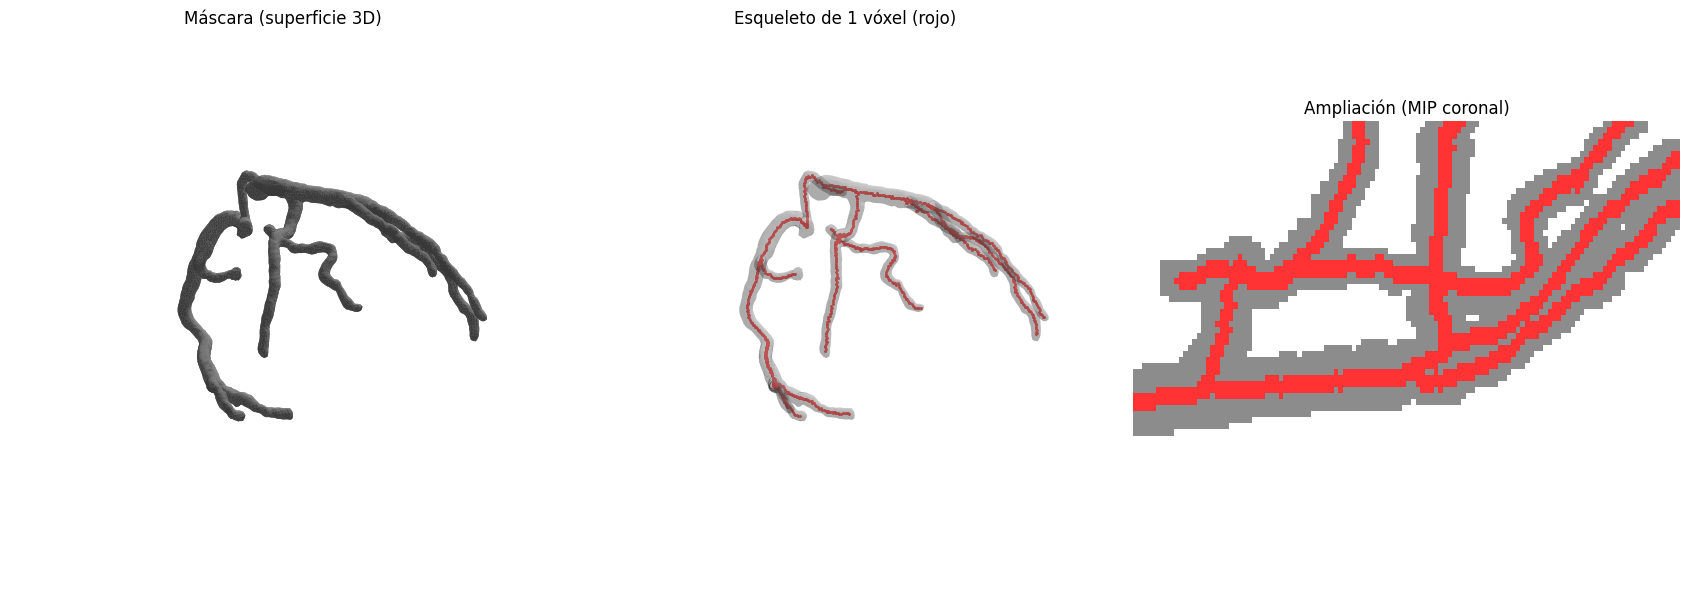

-> fig01_esqueleto_centerline.png


In [7]:
def fig_esqueleto(gt, sp, nombre='fig01_esqueleto_centerline'):
    sl = bbox(gt); g = gt[sl]
    sk = skeletonize(g)
    fig = plt.figure(figsize=(17, 6), facecolor=BG)
    m = malla(g, sp, sigma=1.0, paso=2)
    ax = fig.add_subplot(1, 3, 1, projection='3d', facecolor=BG)
    pts = dibujar_malla(ax, m, GRIS_MALLA); ajustar_3d(ax, pts); ax.set_title('Máscara (superficie 3D)', color=FG)
    ax = fig.add_subplot(1, 3, 2, projection='3d', facecolor=BG)
    pts = dibujar_malla(ax, m, '#555555' if BGV == 0 else '#9a9a9a', alpha=0.25)
    idx = np.argwhere(sk) * np.array(sp)
    ax.scatter(idx[:, 2], idx[:, 1], idx[:, 0], s=1.2, c='#ff4d4d', depthshade=False)
    ajustar_3d(ax, pts); ax.set_title('Esqueleto de 1 vóxel (rojo)', color=FG)
    ax = fig.add_subplot(1, 3, 3, facecolor=BG)
    eje = 1; asp = aspecto(sp, eje)
    m2 = g.any(eje); s2 = ndimage.binary_dilation(sk.any(eje), iterations=1)
    over = np.full(m2.shape + (3,), BGV); over[m2] = 0.55; over[s2] = [1, .2, .2]
    dens = ndimage.uniform_filter(sk.any(eje).astype(float), size=min(100, min(m2.shape)))
    cy, cx = np.unravel_index(np.argmax(dens), dens.shape); h = min(60, min(m2.shape) // 2)
    ax.imshow(over[max(cy - h, 0):cy + h, max(cx - h, 0):cx + h], aspect=asp, interpolation='nearest')
    ax.set_title('Ampliación (MIP coronal)', color=FG); ax.axis('off')
    fig.tight_layout()
    guardar(fig, nombre, 'Marco teórico: clDice y esqueletonización', 'Esqueleto de un vóxel de grosor (centerline) sobre el que se definen Tprec, Tsens y clDice')

caso_ref, fold_ref = ELEGIDOS['C_representativo']
gt_ref, preds_ref, sp_ref = cargar_caso(DS_F, TR_F, caso_ref, fold_ref)
fig_esqueleto(gt_ref, sp_ref)

### Fig. 02. Árbol coronario completo (ground truth)

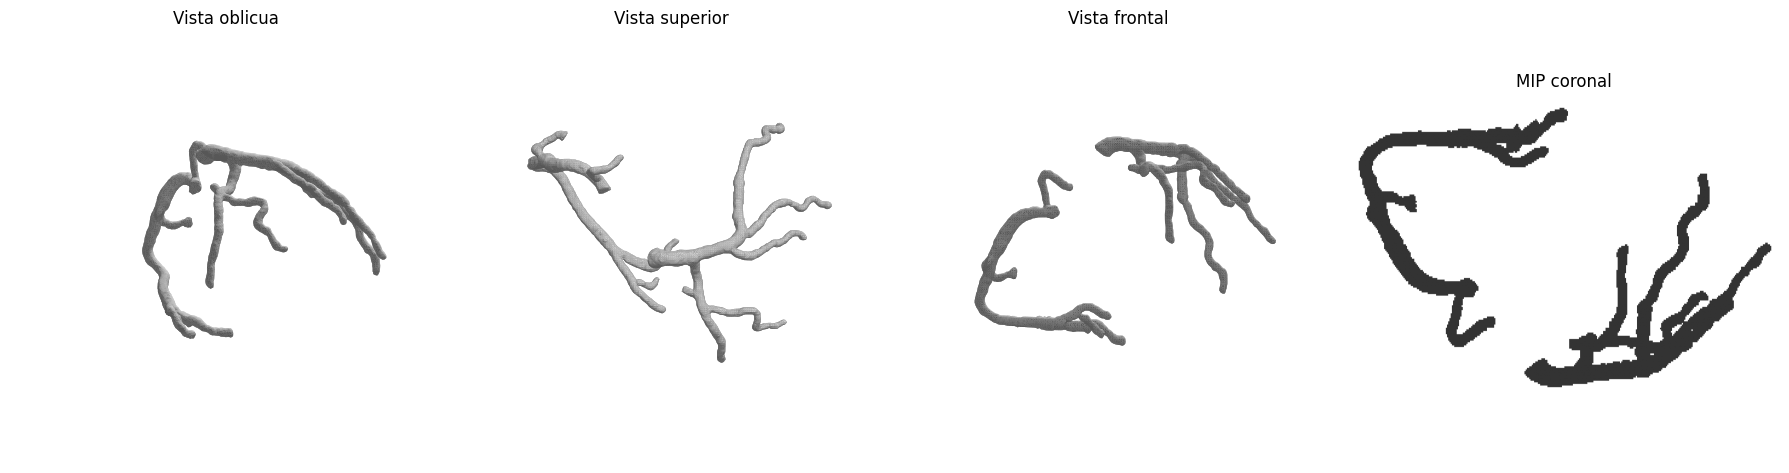

-> fig02_arbol_gt.png


In [8]:
def fig_arbol(gt, sp, nombre='fig02_arbol_gt'):
    sl = bbox(gt); g = gt[sl]; m = malla(g, sp, sigma=1.0, paso=2)
    fig = plt.figure(figsize=(18, 6), facecolor=BG)
    for i, (el, az, t) in enumerate([(20, -60, 'Vista oblicua'), (90, -90, 'Vista superior'), (0, -90, 'Vista frontal')]):
        ax = fig.add_subplot(1, 4, i + 1, projection='3d', facecolor=BG)
        pts = dibujar_malla(ax, m, '#d9d9d9'); ajustar_3d(ax, pts, el, az); ax.set_title(t, color=FG)
    ax = fig.add_subplot(1, 4, 4, facecolor=BG); ax.imshow(mip_rgb(g, 1), aspect=aspecto(sp, 1)); ax.axis('off'); ax.set_title('MIP coronal', color=FG)
    fig.tight_layout()
    guardar(fig, nombre, 'Datos: ImageCAS', 'Anatomía, extensión y finura del árbol coronario anotado')
fig_arbol(gt_ref, sp_ref)

### Fig. 03. CT con contorno del ground truth (requiere `nnUNet_raw/<dataset>/imagesTr`)

In [9]:
def fig_ct(ct, gt, sp, nombre='fig03_ct_gt_tres_vistas'):
    z0, y0, x0 = [int(np.median(i)) for i in np.nonzero(gt)]
    cortes = {'Axial': (ct[z0], gt[z0], sp[1] / sp[2]), 'Coronal': (ct[:, y0], gt[:, y0], sp[0] / sp[2]), 'Sagital': (ct[:, :, x0], gt[:, :, x0], sp[0] / sp[1])}
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.5), facecolor=BG)
    for a, (t, (c, g, asp)) in zip(ax, cortes.items()):
        a.imshow(np.clip(c, -200, 600), cmap='gray', aspect=asp); a.contour(g, levels=[0.5], colors='r', linewidths=0.8)
        a.set_title(t, color=FG); a.axis('off')
    fig.tight_layout()
    guardar(fig, nombre, 'Datos: ImageCAS', 'Aspecto del dato original (CCTA) y de la anotación en las tres vistas')
ct_ref = cargar_ct(DS_F, caso_ref)
if ct_ref is not None and ct_ref.shape == gt_ref.shape: fig_ct(ct_ref, gt_ref, sp_ref)
else: print('CT no disponible o con distinta resolución que el GT preprocesado: se omite la Fig. 03.')

CT no disponible o con distinta resolución que el GT preprocesado: se omite la Fig. 03.


## 4. Justificación del Experimento 3 (v2): grosor de los vasos y deep supervision

**Hipótesis del Experimento 3.** En las escalas reducidas de deep supervision las arterias casi desaparecen y su esqueleto aporta poca información. Esta figura lo cuantifica sobre el ground truth: (a) radio local de los vasos en vóxeles (transformada de distancia evaluada sobre el esqueleto) y (b) fracción de vóxeles de vaso que sobrevive al submuestreo por vecino más cercano en factores 2, 4 y 8, respecto a lo esperado si el vaso se conservara (1/factor³).

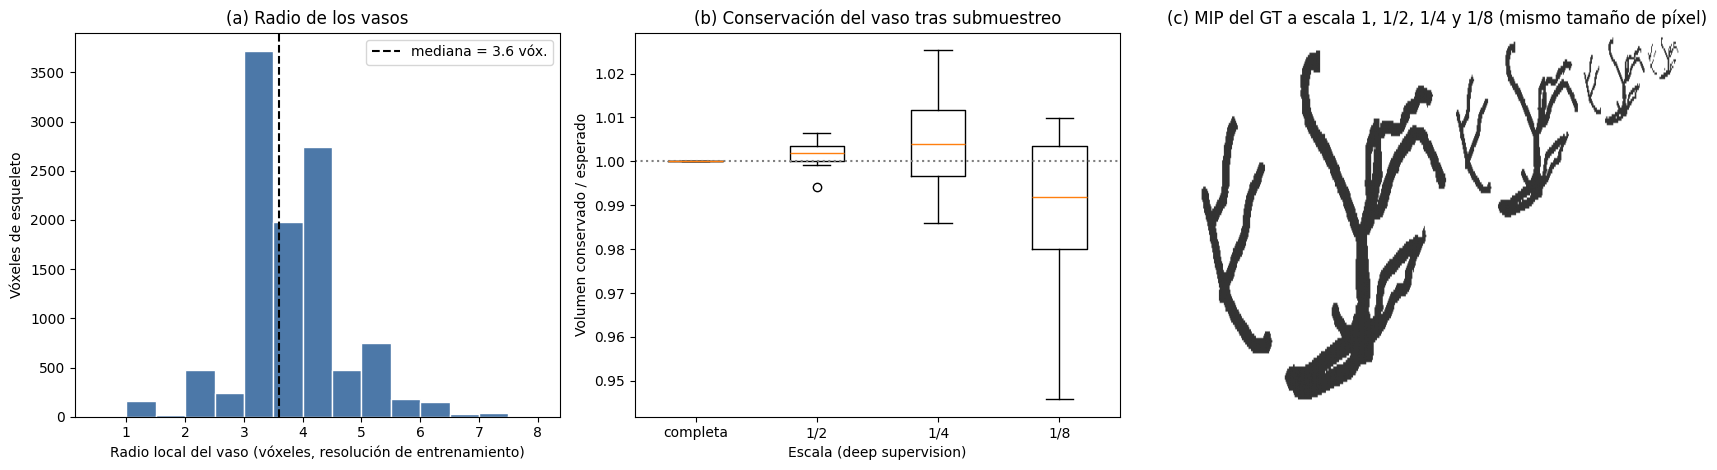

-> fig04_grosor_y_deep_supervision.png


In [10]:
def radios_esqueleto(gt):
    sl = bbox(gt); g = gt[sl]
    edt = ndimage.distance_transform_edt(g)
    return edt[skeletonize(g)]

def supervivencia(gt, factores=(1, 2, 4, 8)):
    res = {}
    for s in factores:
        d = gt[::s, ::s, ::s]
        res[s] = (d.sum() * s ** 3) / max(gt.sum(), 1)
    return res

def fig_grosor(casos_gt, sp, nombre='fig04_grosor_y_deep_supervision'):
    radios = np.concatenate([radios_esqueleto(g) for g in casos_gt])
    sup = pd.DataFrame([supervivencia(g) for g in casos_gt])
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
    ax[0].hist(radios, bins=np.arange(0.5, 8.5, 0.5), color='#4C78A8', edgecolor='w')
    ax[0].axvline(np.median(radios), color='k', ls='--', label=f'mediana = {np.median(radios):.1f} vóx.')
    ax[0].set_xlabel('Radio local del vaso (vóxeles, resolución de entrenamiento)'); ax[0].set_ylabel('Vóxeles de esqueleto'); ax[0].legend(); ax[0].set_title('(a) Radio de los vasos')
    ax[1].boxplot([sup[s] for s in sup.columns], labels=[f'1/{s}' if s > 1 else 'completa' for s in sup.columns])
    ax[1].axhline(1, color='gray', ls=':'); ax[1].set_ylabel('Volumen conservado / esperado'); ax[1].set_xlabel('Escala (deep supervision)'); ax[1].set_title('(b) Conservación del vaso tras submuestreo')
    g = casos_gt[0]; sl = bbox(g)
    fila = [mip_rgb(g[sl][::s, ::s, ::s], 1) for s in (1, 2, 4, 8)]
    ancho = sum(f.shape[1] for f in fila); alto = fila[0].shape[0]
    lienzo = np.full((alto, ancho, 3), BGV); x = 0
    for f in fila:
        lienzo[:f.shape[0], x:x + f.shape[1]] = f; x += f.shape[1] + 0
    ax[2].imshow(lienzo, aspect='auto'); ax[2].axis('off'); ax[2].set_title('(c) MIP del GT a escala 1, 1/2, 1/4 y 1/8 (mismo tamaño de píxel)')
    fig.tight_layout()
    guardar(fig, nombre, 'Experimento 3 (justificación de v2) y discusión', 'Los vasos de 1–3 vóxeles apenas sobreviven en las escalas reducidas de deep supervision', facecolor='white')

muestra = list(df['case_id'].sample(8, random_state=0)); gts = []
for c in muestra:
    f = int(df.loc[df.case_id == c, 'fold'].iloc[0]); gts.append(leer(gt_dir(DS_F) / nombre(c))[0] > 0)
fig_grosor(gts, sp_ref)

## 5. Fase piloto (200 casos, fold 0)

### Fig. 05. Ground truth, baseline, v1 y v2 en dos casos del piloto
Mayor mejora y mayor empeoramiento de clDice de v1 frente al baseline (apartado de resultados del piloto).

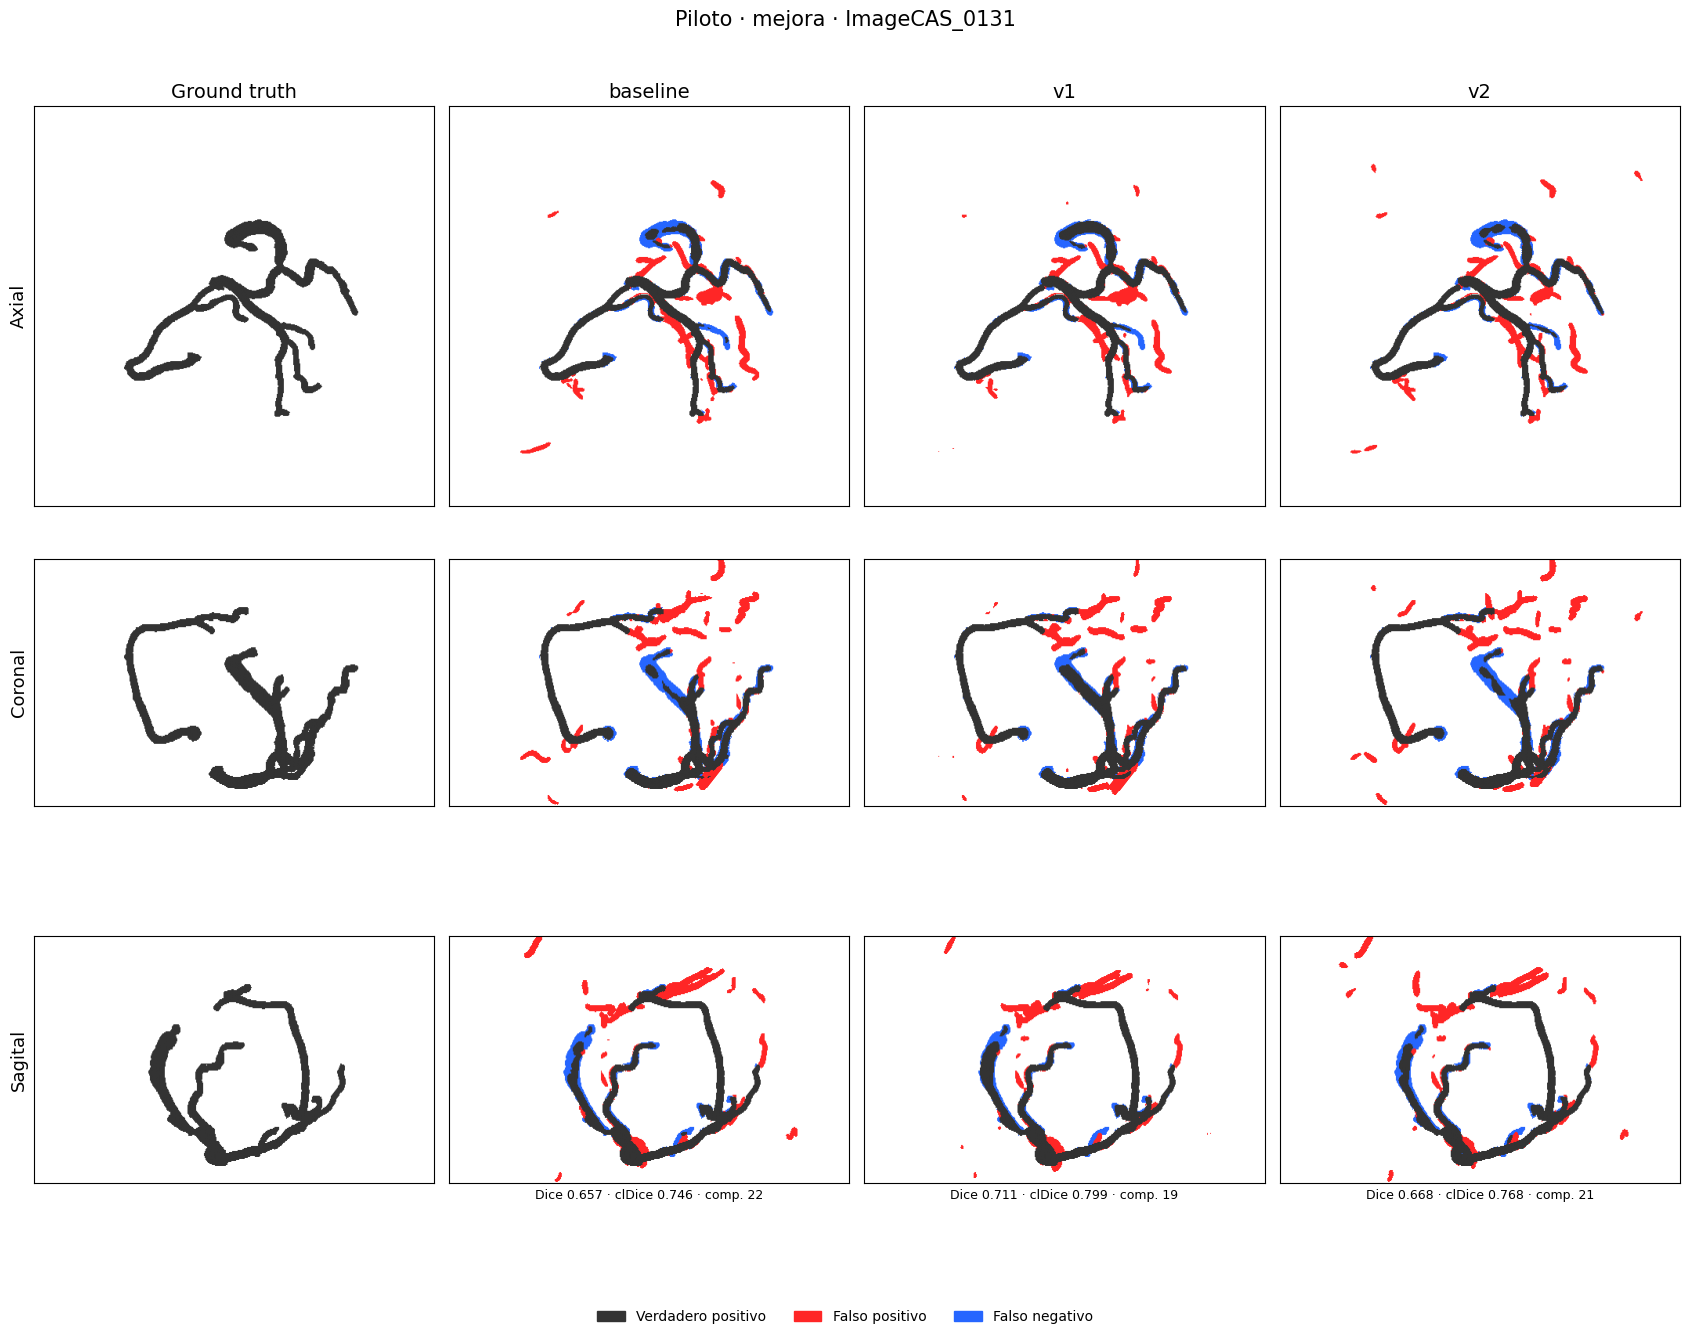

-> fig05_piloto_mejora_ImageCAS_0131.png


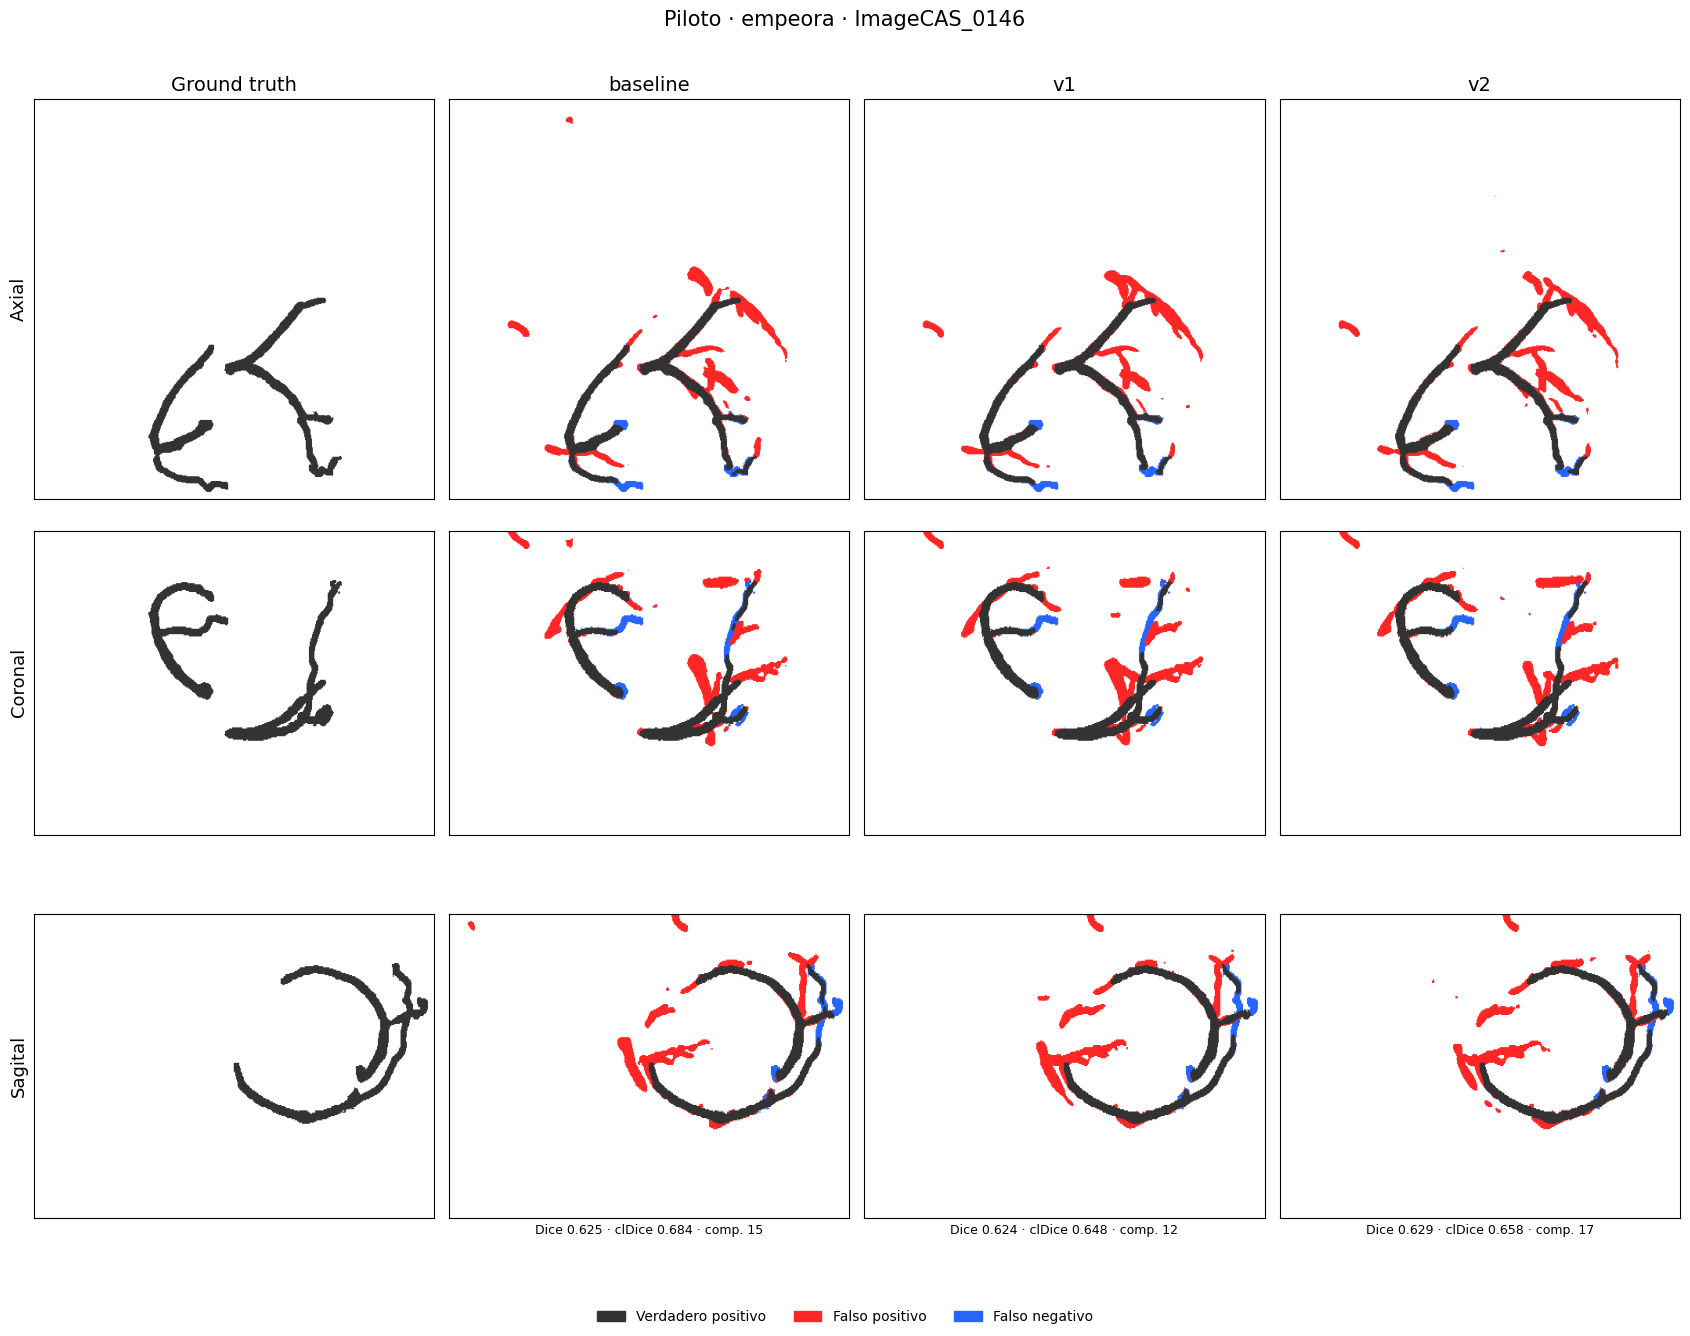

-> fig05_piloto_empeora_ImageCAS_0146.png


In [11]:
def fig_cuatro_modelos(case_id, etiqueta, fila_metricas, nombre):
    gt, preds, sp = cargar_caso(DS_P, TR_P, case_id, 0)
    cols = [('Ground truth', None)] + [(k, preds[k]) for k in ('baseline', 'v1', 'v2')]
    fig, axes = plt.subplots(3, 4, figsize=(17, 13.5), facecolor=BG)
    for i, (v, eje) in enumerate(VISTAS.items()):
        asp = aspecto(sp, eje)
        for j, (t, p) in enumerate(cols):
            axes[i, j].imshow(mip_rgb(gt, eje) if p is None else clases_rgb(p, gt, eje), aspect=asp)
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
            if i == 0: axes[i, j].set_title(t, color=FG, fontsize=14)
        axes[i, 0].set_ylabel(v, color=FG, fontsize=13)
    for j, k in enumerate(('baseline', 'v1_lam02', 'v2_lam02'), start=1):
        r = fila_metricas[k]
        axes[2, j].set_xlabel(f"Dice {r['dice']:.3f} · clDice {r['cldice']:.3f} · comp. {int(r['n_componentes'])}", color=FG, fontsize=9)
    fig.legend(handles=LEYENDA_CLASES, loc='lower center', ncol=3, facecolor=BG, labelcolor=FG, frameon=False)
    fig.suptitle(f'Piloto · {etiqueta} · {case_id}', color=FG, fontsize=15); fig.tight_layout(rect=[0, 0.03, 1, 0.97])
    guardar(fig, nombre, 'Resultados de la fase piloto', 'Comparación visual de baseline, v1 y v2 frente al ground truth')

for k, c in ELEGIDOS_PILOTO.items():
    fila = {m: dfp[(dfp.case_id == c) & (dfp.modelo == m)].iloc[0] for m in ('baseline', 'v1_lam02', 'v2_lam02')}
    fig_cuatro_modelos(c, k, fila, f'fig05_piloto_{k}_{c}')

### Fig. 06. Distribución por caso de las métricas del piloto

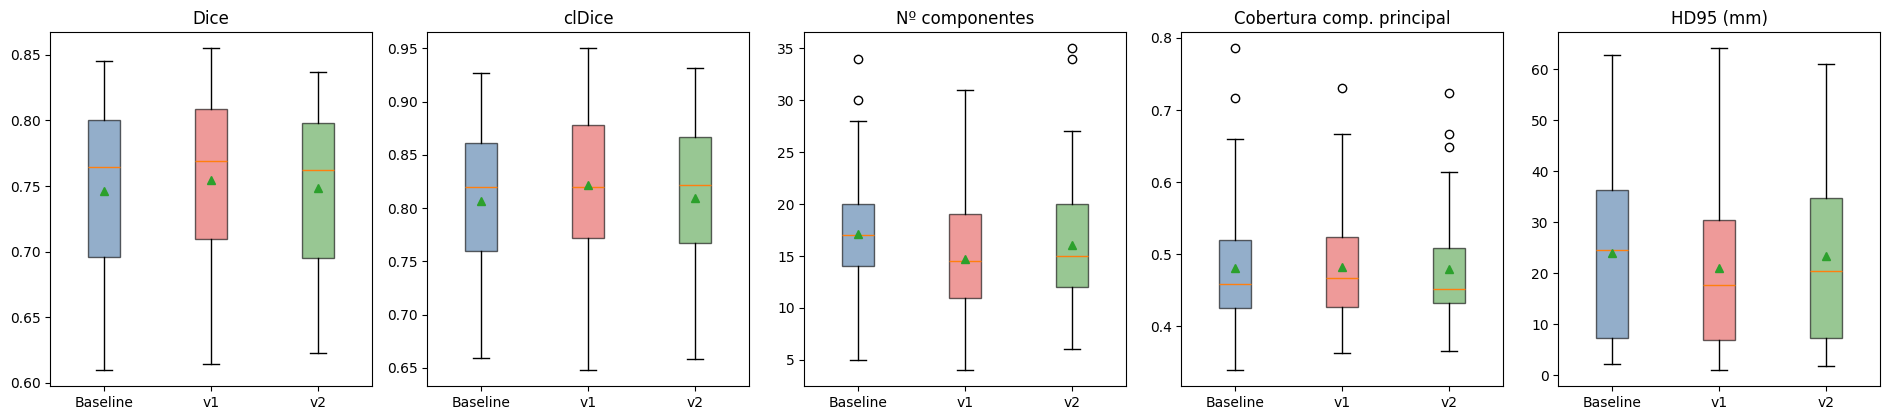

-> fig06_piloto_distribucion_metricas.png


In [12]:
def fig_piloto_dist(nombre='fig06_piloto_distribucion_metricas'):
    mets = [('dice', 'Dice'), ('cldice', 'clDice'), ('n_componentes', 'Nº componentes'), ('cobertura_principal', 'Cobertura comp. principal'), ('hd95_crudo_mm', 'HD95 (mm)')]
    modelos = ['baseline', 'v1_lam02', 'v2_lam02']; etiq = ['Baseline', 'v1', 'v2']
    fig, ax = plt.subplots(1, len(mets), figsize=(19, 4.3))
    for a, (c, t) in zip(ax, mets):
        datos = [dfp[dfp.modelo == m][c].dropna() for m in modelos]
        bp = a.boxplot(datos, labels=etiq, patch_artist=True, showmeans=True)
        for patch, col in zip(bp['boxes'], [COL['baseline'], COL['v1'], COL['v2']]): patch.set_facecolor(col); patch.set_alpha(0.6)
        a.set_title(t)
    fig.tight_layout()
    guardar(fig, nombre, 'Resultados de la fase piloto', 'Dispersión entre casos (n = 40) que la media de la tabla no muestra', facecolor='white')
fig_piloto_dist()

### Fig. 07. Métricas medias por valor de λ (piloto)

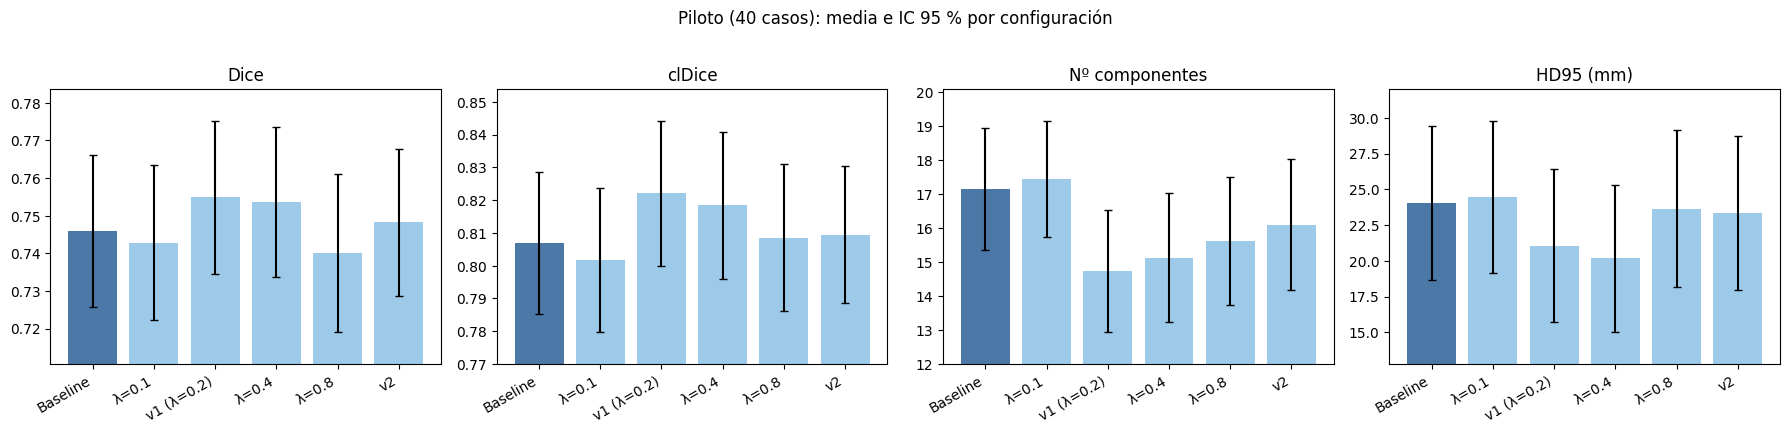

-> fig07_piloto_barrido_lambda.png


In [13]:
def fig_lambda(nombre='fig07_piloto_barrido_lambda'):
    orden = [m for m in ['baseline', 'lam01', 'v1_lam02', 'lam04', 'lam08', 'v2_lam02'] if m in set(dfp.modelo)]
    etq = {'baseline': 'Baseline', 'lam01': 'λ=0.1', 'v1_lam02': 'v1 (λ=0.2)', 'lam04': 'λ=0.4', 'lam08': 'λ=0.8', 'v2_lam02': 'v2'}
    mets = [('dice', 'Dice'), ('cldice', 'clDice'), ('n_componentes', 'Nº componentes'), ('hd95_crudo_mm', 'HD95 (mm)')]
    fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
    for a, (c, t) in zip(ax, mets):
        g = dfp.groupby('modelo')[c].agg(['mean', 'sem']).loc[orden]
        a.bar(range(len(orden)), g['mean'], yerr=1.96 * g['sem'], color=[COL.get(m.split('_')[0], '#999999') if m in COL else '#9ecae9' for m in orden], capsize=3)
        a.set_xticks(range(len(orden))); a.set_xticklabels([etq[m] for m in orden], rotation=30, ha='right'); a.set_title(t)
        lo, hi = (g['mean'] - 1.96 * g['sem']).min(), (g['mean'] + 1.96 * g['sem']).max(); a.set_ylim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))
    fig.suptitle('Piloto (40 casos): media e IC 95 % por configuración', y=1.02); fig.tight_layout()
    guardar(fig, nombre, 'Selección de λ (piloto)', 'Barrido manual de λ: diferencias pequeñas entre valores', facecolor='white')
fig_lambda()

## 6. Experimento principal (1.000 casos): figuras cuantitativas

### Fig. 08. Distribución de Δ por métrica (pooled)

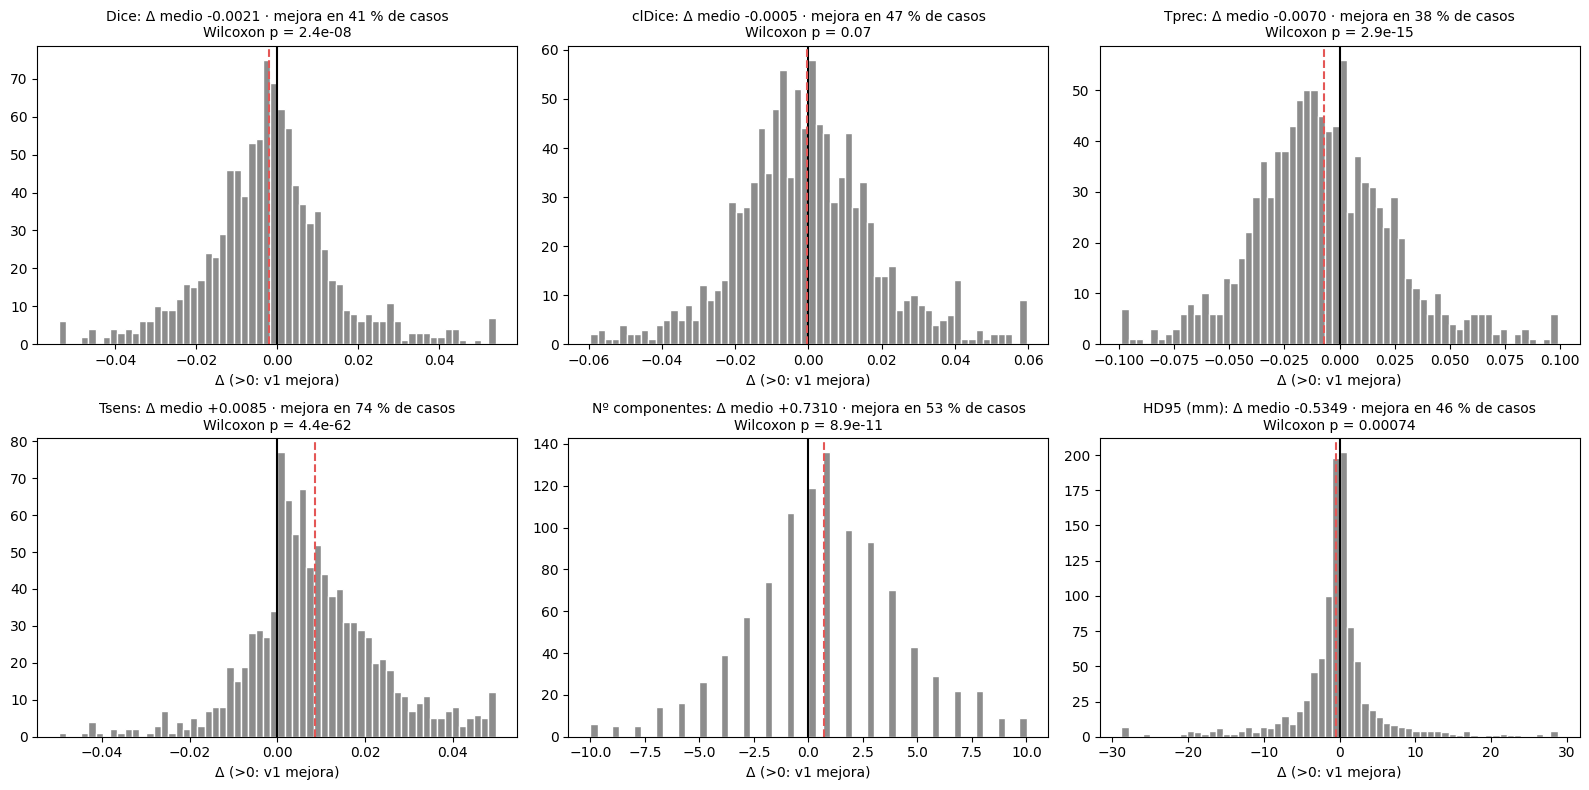

-> fig08_1000_distribucion_delta.png


In [14]:
def fig_delta_dist(nombre='fig08_1000_distribucion_delta'):
    fig, ax = plt.subplots(2, 3, figsize=(16, 8))
    for a, (c, (t, o)) in zip(ax.ravel(), METRICAS.items()):
        d = df['delta_' + c].dropna(); lim = np.percentile(np.abs(d), 99)
        a.hist(d.clip(-lim, lim), bins=60, color='#8c8c8c', edgecolor='w'); a.axvline(0, color='k'); a.axvline(d.mean(), color=COL['v1'], ls='--')
        p = stats.wilcoxon(d).pvalue
        a.set_title(f'{t}: Δ medio {d.mean():+.4f} · mejora en {100 * (d > 0).mean():.0f} % de casos\nWilcoxon p = {p:.2g}', fontsize=10)
        a.set_xlabel('Δ (>0: v1 mejora)')
    fig.tight_layout()
    guardar(fig, nombre, 'Resultado agregado (1.000 casos)', 'Magnitud del efecto por caso y proporción de casos en que v1 mejora', facecolor='white')
fig_delta_dist()

### Fig. 09. Δ medio por fold (intervalo de confianza del 95 %)

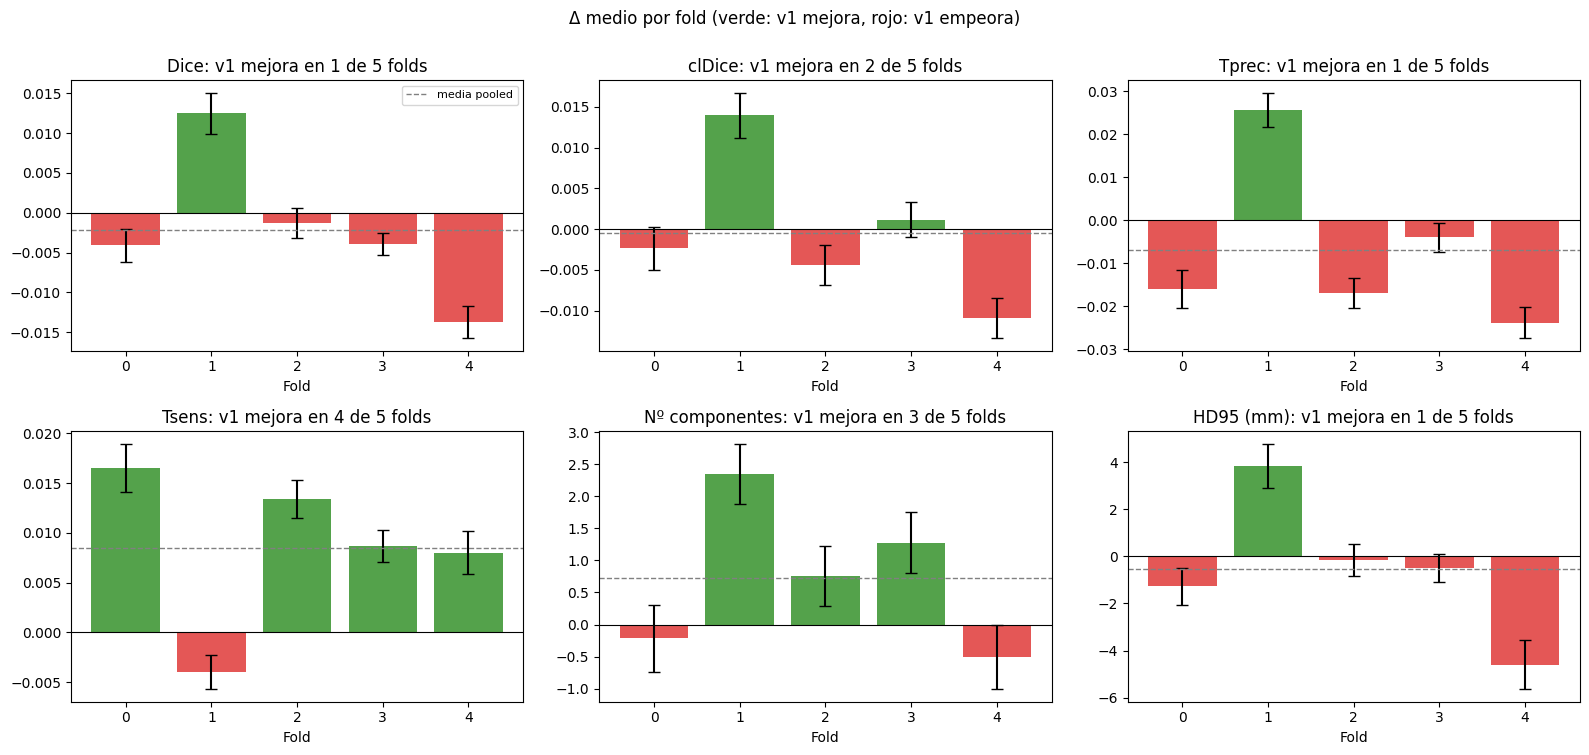

-> fig09_1000_delta_por_fold.png


In [15]:
def fig_delta_fold(nombre='fig09_1000_delta_por_fold'):
    fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
    for a, (c, (t, o)) in zip(ax.ravel(), METRICAS.items()):
        g = df.groupby('fold')['delta_' + c].agg(['mean', 'sem'])
        cols = ['#54A24B' if m > 0 else '#E45756' for m in g['mean']]
        a.bar(g.index, g['mean'], yerr=1.96 * g['sem'], color=cols, capsize=4); a.axhline(0, color='k', lw=0.8)
        a.axhline(df['delta_' + c].mean(), color='gray', ls='--', lw=1, label='media pooled')
        a.set_title(f'{t}: v1 mejora en {(g["mean"] > 0).sum()} de 5 folds'); a.set_xlabel('Fold'); a.set_xticks(range(5))
    ax[0, 0].legend(fontsize=8)
    fig.suptitle('Δ medio por fold (verde: v1 mejora, rojo: v1 empeora)', y=1.0); fig.tight_layout()
    guardar(fig, nombre, 'Resultado por fold (1.000 casos)', 'Consistencia del efecto entre particiones', facecolor='white')
fig_delta_fold()

### Fig. 10. Compromiso entre precisión y sensibilidad topológicas

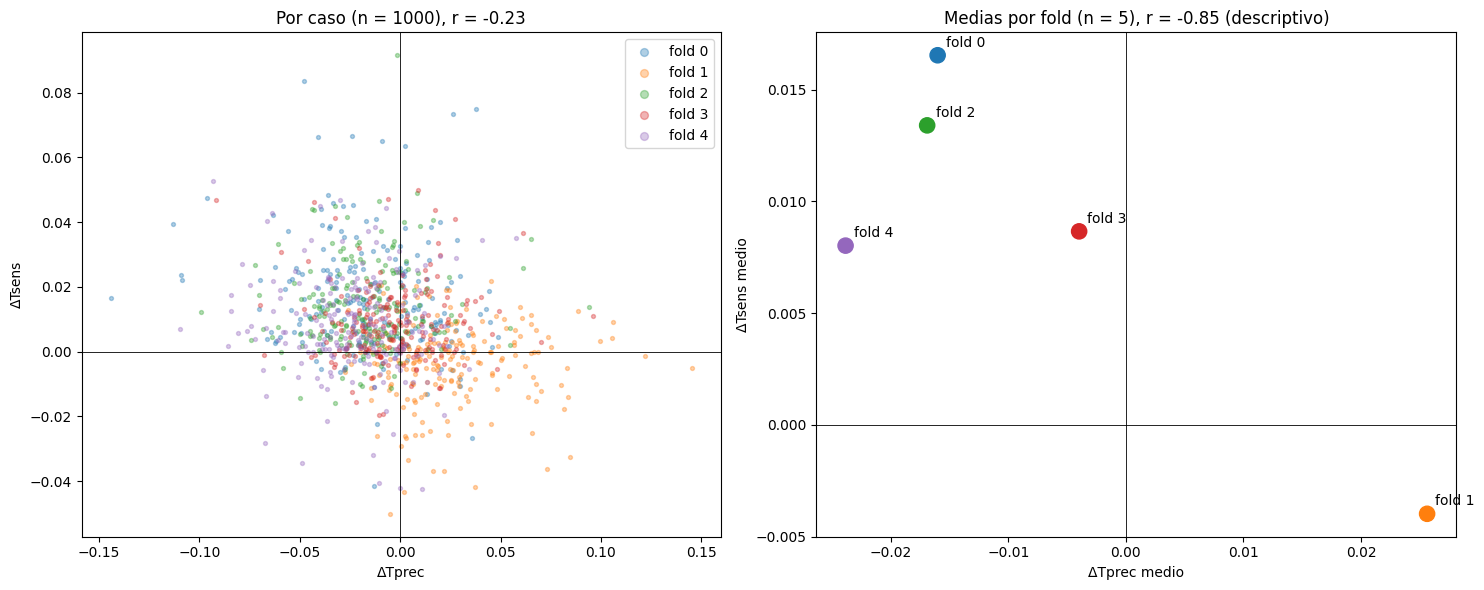

-> fig10_1000_tradeoff_tprec_tsens.png


In [16]:
def fig_tradeoff(nombre='fig10_1000_tradeoff_tprec_tsens'):
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    cm = plt.get_cmap('tab10')
    for f in FOLDS:
        s = df[df.fold == f]; ax[0].scatter(s['delta_topo_precision'], s['delta_topo_sensitivity'], s=8, alpha=0.35, color=cm(f), label=f'fold {f}')
    r = df[['delta_topo_precision', 'delta_topo_sensitivity']].corr().iloc[0, 1]
    ax[0].axhline(0, color='k', lw=0.6); ax[0].axvline(0, color='k', lw=0.6)
    ax[0].set_xlabel('ΔTprec'); ax[0].set_ylabel('ΔTsens'); ax[0].set_title(f'Por caso (n = {len(df)}), r = {r:.2f}'); ax[0].legend(markerscale=2)
    g = df.groupby('fold')[['delta_topo_precision', 'delta_topo_sensitivity']].mean()
    ax[1].scatter(g.iloc[:, 0], g.iloc[:, 1], s=120, c=[cm(f) for f in g.index])
    for f, (x, y) in g.iterrows(): ax[1].annotate(f'fold {f}', (x, y), textcoords='offset points', xytext=(6, 6))
    rf = np.corrcoef(g.iloc[:, 0], g.iloc[:, 1])[0, 1]
    ax[1].axhline(0, color='k', lw=0.6); ax[1].axvline(0, color='k', lw=0.6)
    ax[1].set_xlabel('ΔTprec medio'); ax[1].set_ylabel('ΔTsens medio'); ax[1].set_title(f'Medias por fold (n = 5), r = {rf:.2f} (descriptivo)')
    fig.tight_layout()
    guardar(fig, nombre, 'Resultado por fold (1.000 casos)', 'v1 intercambia precisión topológica por sensibilidad topológica', facecolor='white')
fig_tradeoff()

### Fig. 11. Componentes conexas y clDice: baseline frente a v1

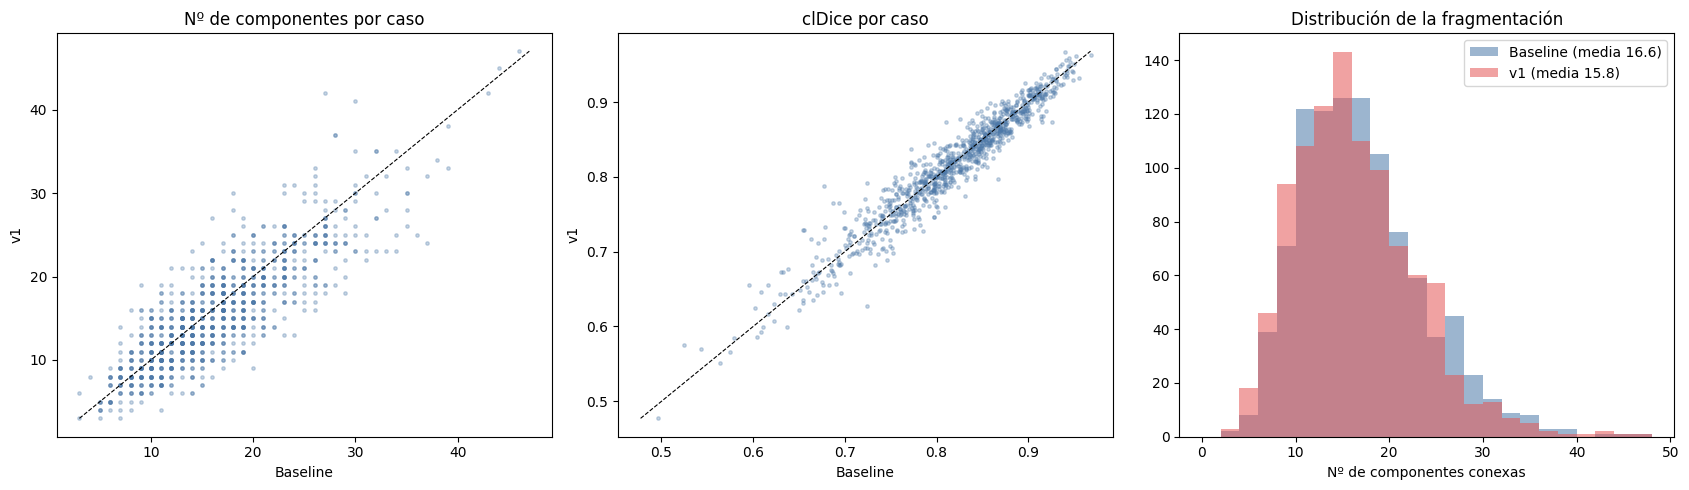

-> fig11_1000_componentes_cldice_pareado.png


In [17]:
def fig_pareado(nombre='fig11_1000_componentes_cldice_pareado'):
    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    for a, c, t in ((ax[0], 'n_componentes', 'Nº de componentes por caso'), (ax[1], 'cldice', 'clDice por caso')):
        x, y = df[c + '_baseline'], df[c + '_v1']; lim = [min(x.min(), y.min()), max(x.max(), y.max())]
        a.scatter(x, y, s=6, alpha=0.3, color='#4C78A8'); a.plot(lim, lim, 'k--', lw=0.8); a.set_xlabel('Baseline'); a.set_ylabel('v1'); a.set_title(t)
    b = np.arange(0, df[['n_componentes_baseline', 'n_componentes_v1']].max().max() + 2, 2)
    ax[2].hist(df['n_componentes_baseline'], bins=b, alpha=0.55, color=COL['baseline'], label=f"Baseline (media {df['n_componentes_baseline'].mean():.1f})")
    ax[2].hist(df['n_componentes_v1'], bins=b, alpha=0.55, color=COL['v1'], label=f"v1 (media {df['n_componentes_v1'].mean():.1f})")
    ax[2].set_xlabel('Nº de componentes conexas'); ax[2].set_title('Distribución de la fragmentación'); ax[2].legend()
    fig.tight_layout()
    guardar(fig, nombre, 'Resultado agregado (1.000 casos)', 'Efecto de v1 sobre la fragmentación y sobre clDice caso a caso', facecolor='white')
fig_pareado()

## 7. Análisis cualitativo (casos A, B y C del experimento principal)

### Figs. 12–14. Comparación a tres bandas en las tres vistas

**Criterio de color.** Verdadero positivo: vóxel predicho y presente en el ground truth. Falso positivo (falso negativo): vóxel predicho (anotado) a más de `TOL` = 1 vóxel de la otra máscara; así, la diferencia de grosor de borde, inherente a cualquier segmentación y del orden del propio vóxel, no se cuenta como error. Al proyectar (MIP) un píxel se pinta como acierto si algún vóxel del rayo lo es; después, falso positivo y, por último, falso negativo. Con `TOL = 0` se obtiene la clasificación exacta vóxel a vóxel.

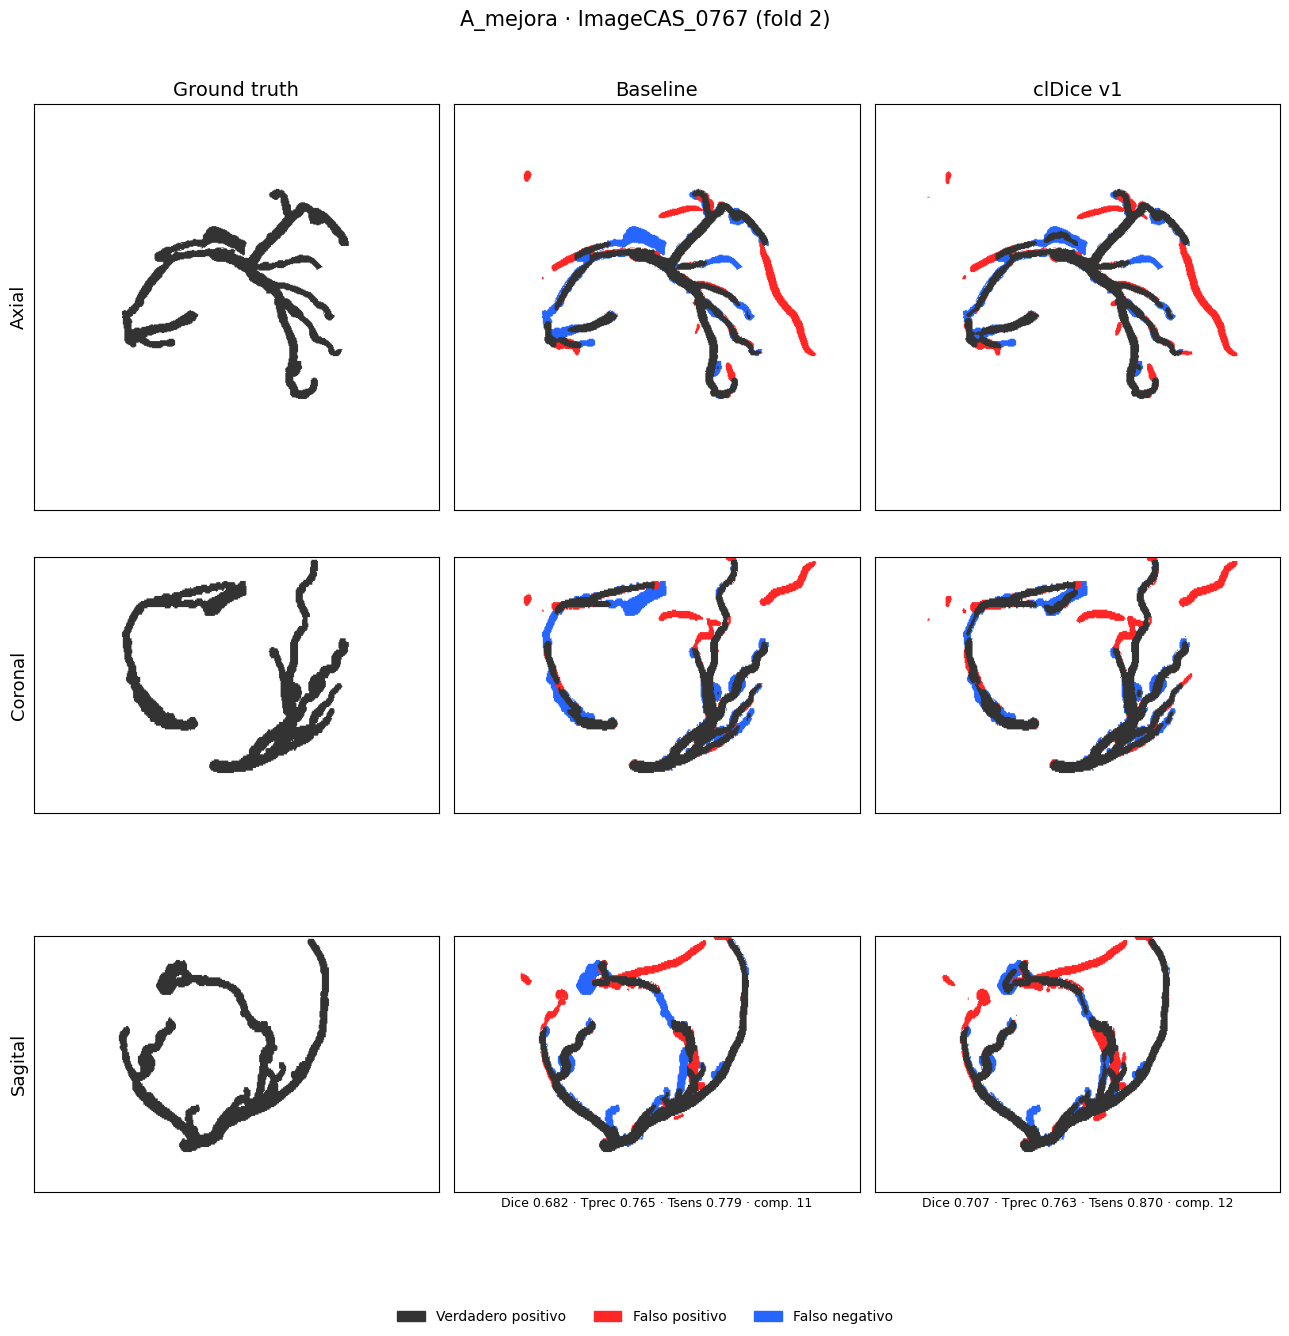

-> fig12_A_mejora_ImageCAS_0767.png


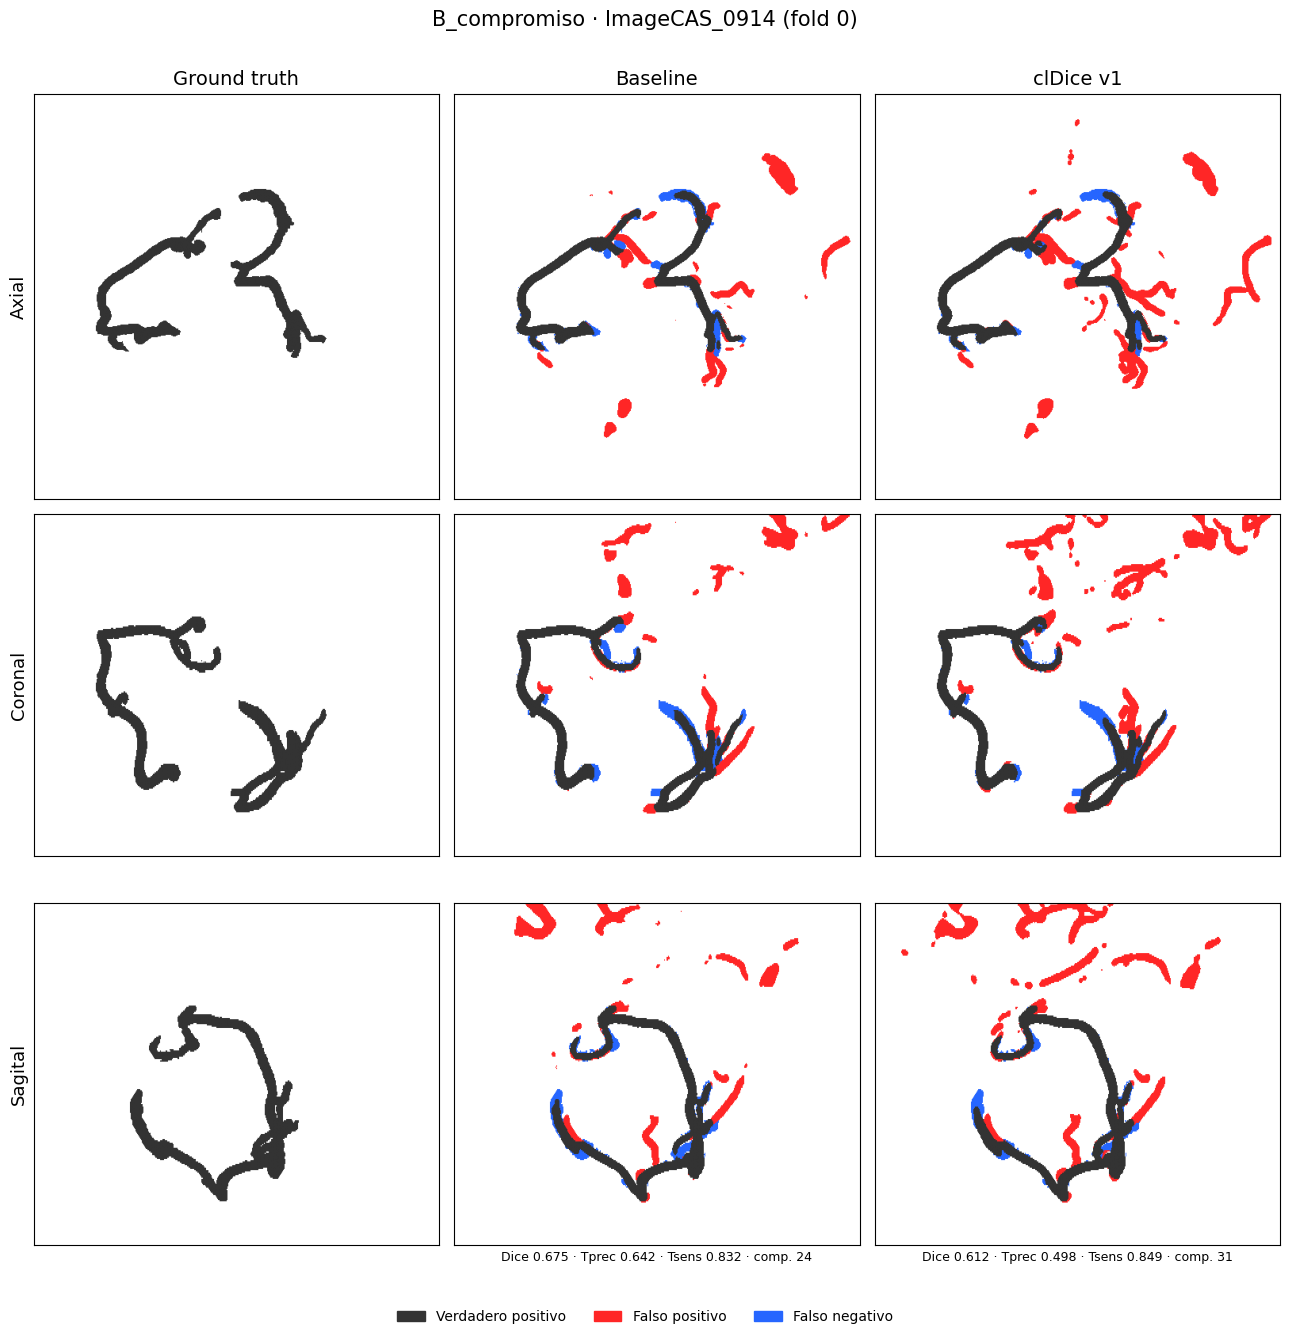

-> fig13_B_compromiso_ImageCAS_0914.png


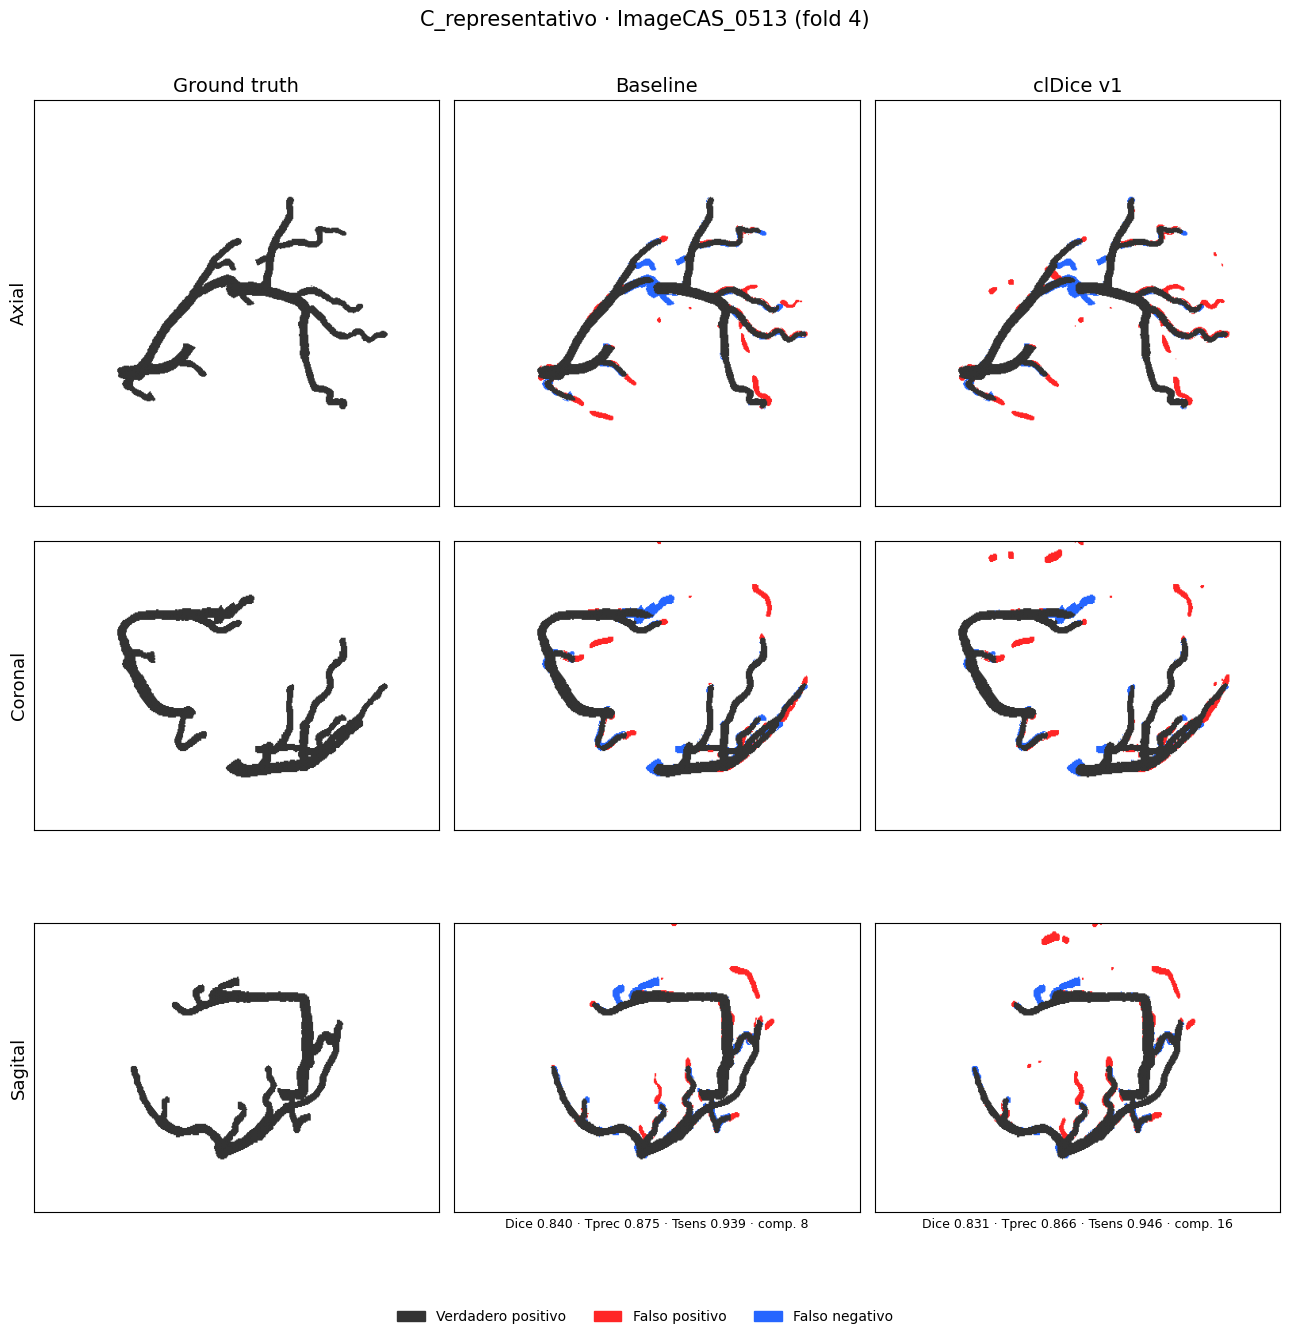

-> fig14_C_representativo_ImageCAS_0513.png


In [18]:
def fig_tres_bandas(etiqueta, case_id, fold, fila, nombre):
    gt, preds, sp = cargar_caso(DS_F, TR_F, case_id, fold)
    fig, axes = plt.subplots(3, 3, figsize=(13, 13.5), facecolor=BG)
    for i, (v, eje) in enumerate(VISTAS.items()):
        asp = aspecto(sp, eje)
        axes[i, 0].imshow(mip_rgb(gt, eje), aspect=asp); axes[i, 1].imshow(clases_rgb(preds['baseline'], gt, eje), aspect=asp); axes[i, 2].imshow(clases_rgb(preds['v1'], gt, eje), aspect=asp)
        axes[i, 0].set_ylabel(v, color=FG, fontsize=13)
    for j, t in enumerate(['Ground truth', 'Baseline', 'clDice v1']): axes[0, j].set_title(t, color=FG, fontsize=14)
    axes[2, 1].set_xlabel(resumen_caso(fila, '_baseline'), color=FG, fontsize=9); axes[2, 2].set_xlabel(resumen_caso(fila, '_v1'), color=FG, fontsize=9)
    for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
    fig.legend(handles=LEYENDA_CLASES, loc='lower center', ncol=3, facecolor=BG, labelcolor=FG, frameon=False)
    fig.suptitle(f'{etiqueta} · {case_id} (fold {fold})', color=FG, fontsize=15); fig.tight_layout(rect=[0, 0.03, 1, 0.97])
    guardar(fig, nombre, 'Discusión: análisis cualitativo', f'Caso {etiqueta}: ground truth, baseline y v1 con TP, FP y FN')

orden_fig = {'A_mejora': 12, 'B_compromiso': 13, 'C_representativo': 14}
for _, fila in sel.iterrows():
    fig_tres_bandas(fila['etiqueta'], fila['case_id'], int(fila['fold']), fila, f"fig{orden_fig[fila['etiqueta']]}_{fila['etiqueta']}_{fila['case_id']}")

### Figs. 15–17. Mapas de diferencia entre v1 y baseline

Cada vóxel se clasifica según el cambio de v1 respecto al baseline, siempre frente al ground truth: **ganancia** (vaso del GT que el baseline omite y v1 recupera, verde), **pérdida** (vaso del GT que el baseline acierta y v1 omite, magenta) y **estructura añadida** (falso positivo de v1 que el baseline no tiene, rojo).

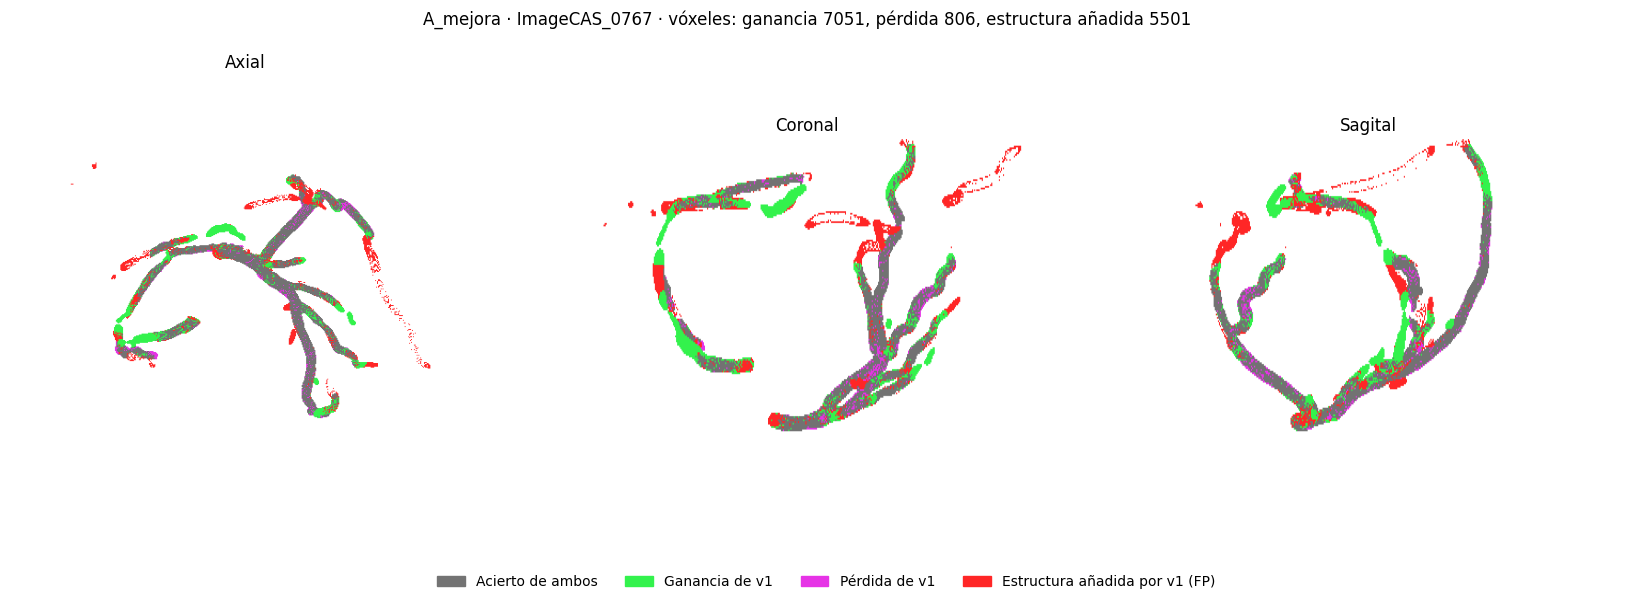

-> fig15_diferencia_A_mejora_ImageCAS_0767.png


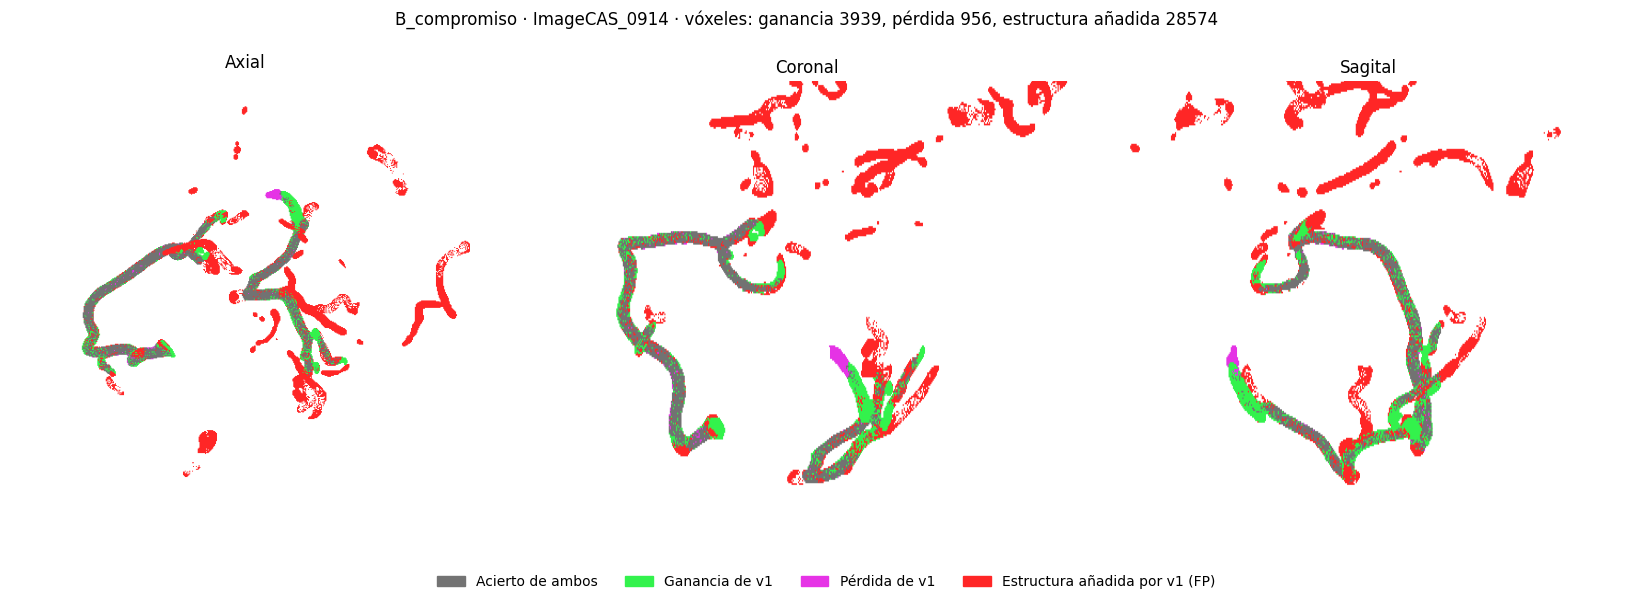

-> fig16_diferencia_B_compromiso_ImageCAS_0914.png


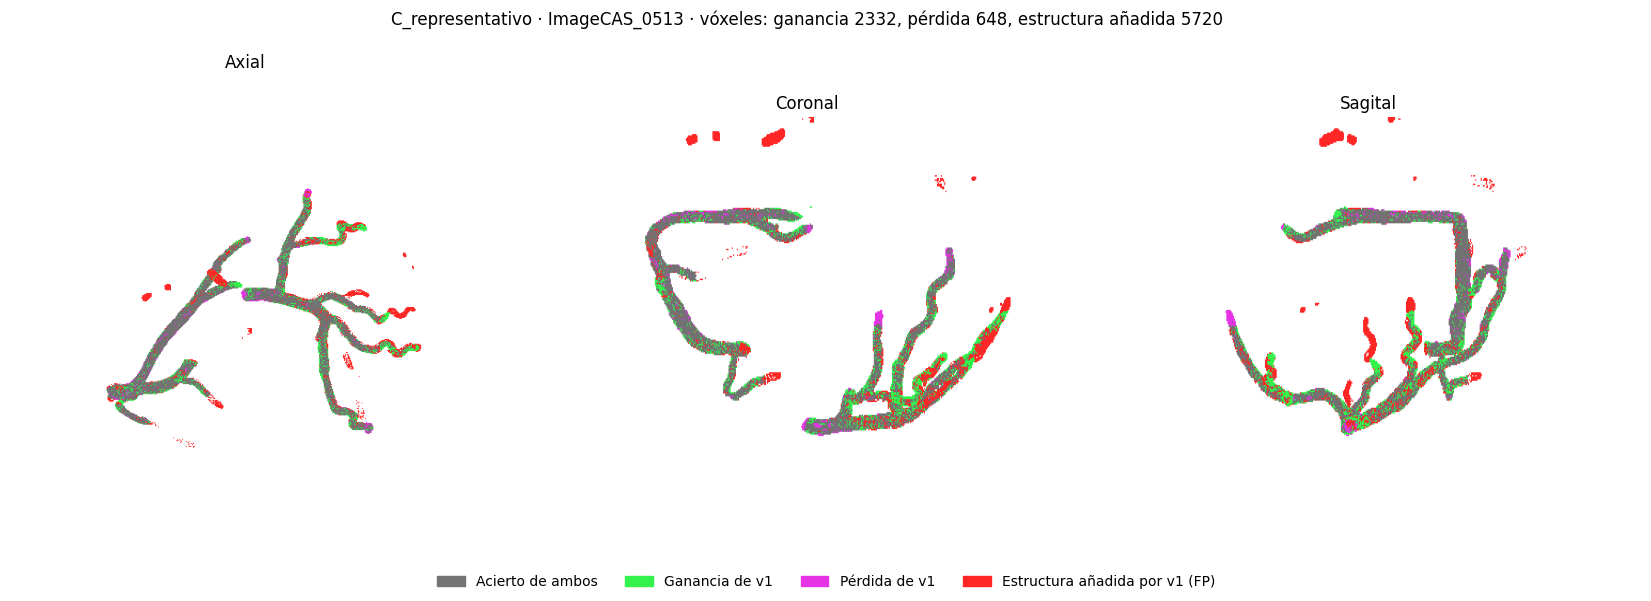

-> fig17_diferencia_C_representativo_ImageCAS_0513.png


In [19]:
def mapa_diferencia(base, v1, gt, eje):
    gan = (v1 & gt & ~base).any(eje); per = (base & gt & ~v1).any(eje); fpn = (v1 & ~gt & ~base).any(eje); com = (base & v1 & gt).any(eje)
    rgb = np.full(gan.shape + (3,), BGV); rgb[com] = [.45, .45, .45]
    rgb[per] = [.9, .2, .9]; rgb[fpn] = [1, .15, .15]; rgb[gan] = [.2, .95, .3]
    return rgb, int(gan.sum()), int(per.sum()), int(fpn.sum())

LEYENDA_DIF = [Patch(color=(.45, .45, .45), label='Acierto de ambos'), Patch(color=(.2, .95, .3), label='Ganancia de v1'),
               Patch(color=(.9, .2, .9), label='Pérdida de v1'), Patch(color=(1, .15, .15), label='Estructura añadida por v1 (FP)')]

def fig_diferencia(etiqueta, case_id, fold, nombre):
    gt, preds, sp = cargar_caso(DS_F, TR_F, case_id, fold)
    fig, axes = plt.subplots(1, 3, figsize=(17, 6), facecolor=BG)
    for a, (v, eje) in zip(axes, VISTAS.items()):
        rgb, g, p, f = mapa_diferencia(preds['baseline'], preds['v1'], gt, eje)
        a.imshow(rgb, aspect=aspecto(sp, eje)); a.set_title(v, color=FG); a.axis('off')
    vox = {'ganancia': int((preds['v1'] & gt & ~preds['baseline']).sum()), 'pérdida': int((preds['baseline'] & gt & ~preds['v1']).sum()), 'añadida': int((preds['v1'] & ~gt & ~preds['baseline']).sum())}
    fig.legend(handles=LEYENDA_DIF, loc='lower center', ncol=4, facecolor=BG, labelcolor=FG, frameon=False)
    fig.suptitle(f'{etiqueta} · {case_id} · vóxeles: ganancia {vox["ganancia"]}, pérdida {vox["pérdida"]}, estructura añadida {vox["añadida"]}', color=FG)
    fig.tight_layout(rect=[0, 0.06, 1, 0.95])
    guardar(fig, nombre, 'Discusión: análisis cualitativo', f'Caso {etiqueta}: dónde ganan y dónde pierden baseline y v1')

orden_dif = {'A_mejora': 15, 'B_compromiso': 16, 'C_representativo': 17}
for _, fila in sel.iterrows():
    fig_diferencia(fila['etiqueta'], fila['case_id'], int(fila['fold']), f"fig{orden_dif[fila['etiqueta']]}_diferencia_{fila['etiqueta']}_{fila['case_id']}")

### Figs. 18–20. Componentes conexas codificadas por color

Cada componente conexa (conectividad de 26 vecinos, la misma de las métricas) recibe un color; la mayor se muestra en blanco. Ilustra de forma directa la fragmentación que cuantifica el número de componentes.

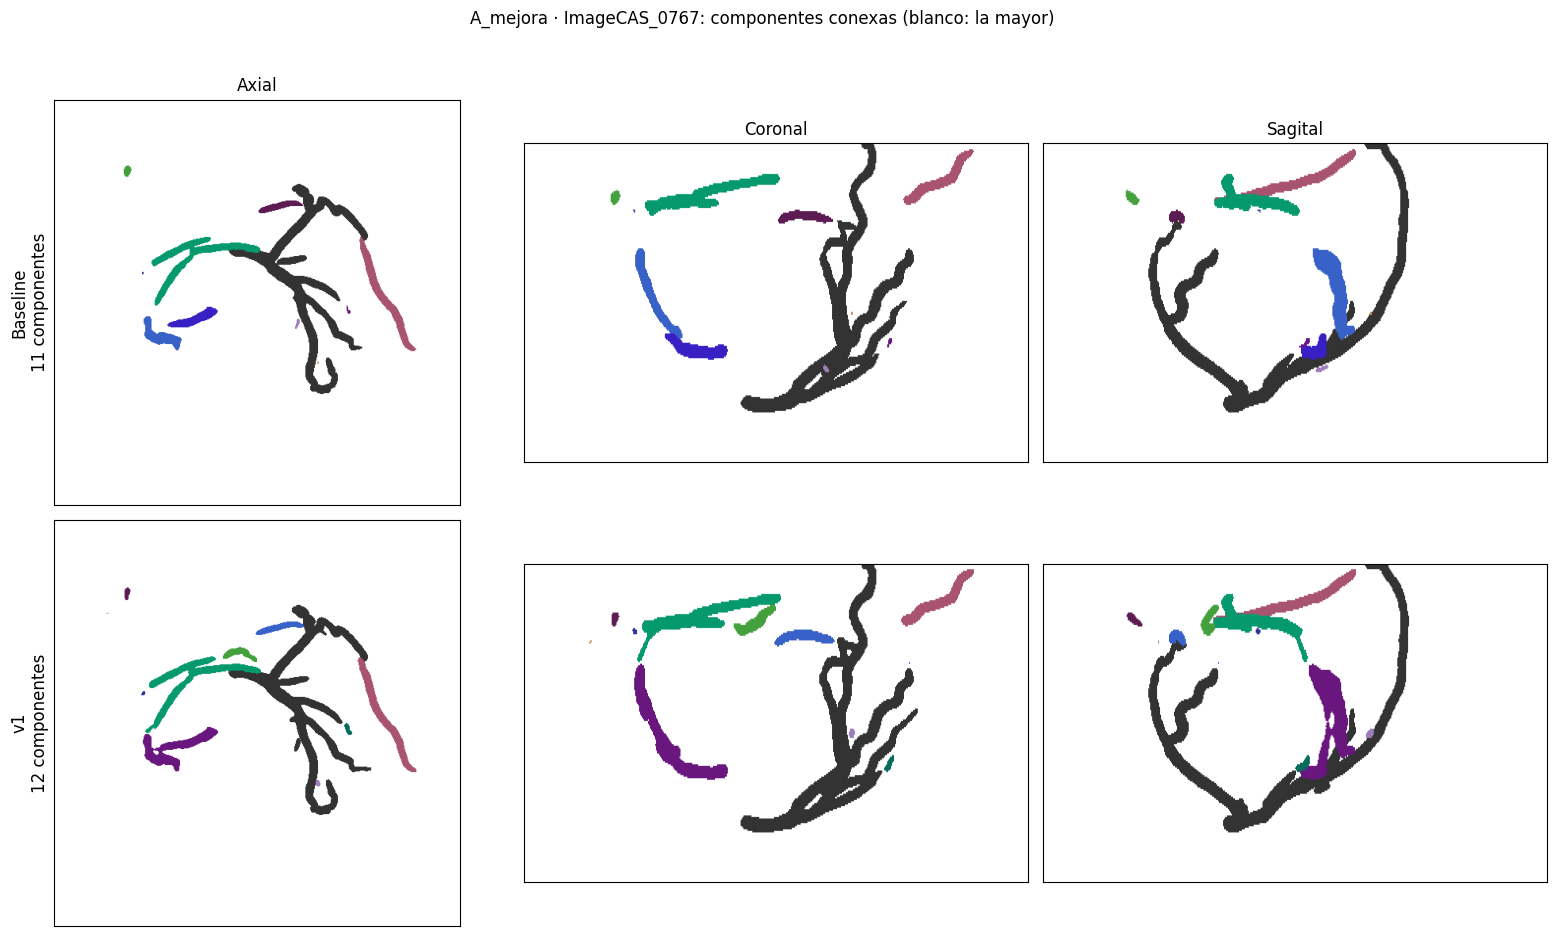

-> fig18_componentes_A_mejora_ImageCAS_0767.png


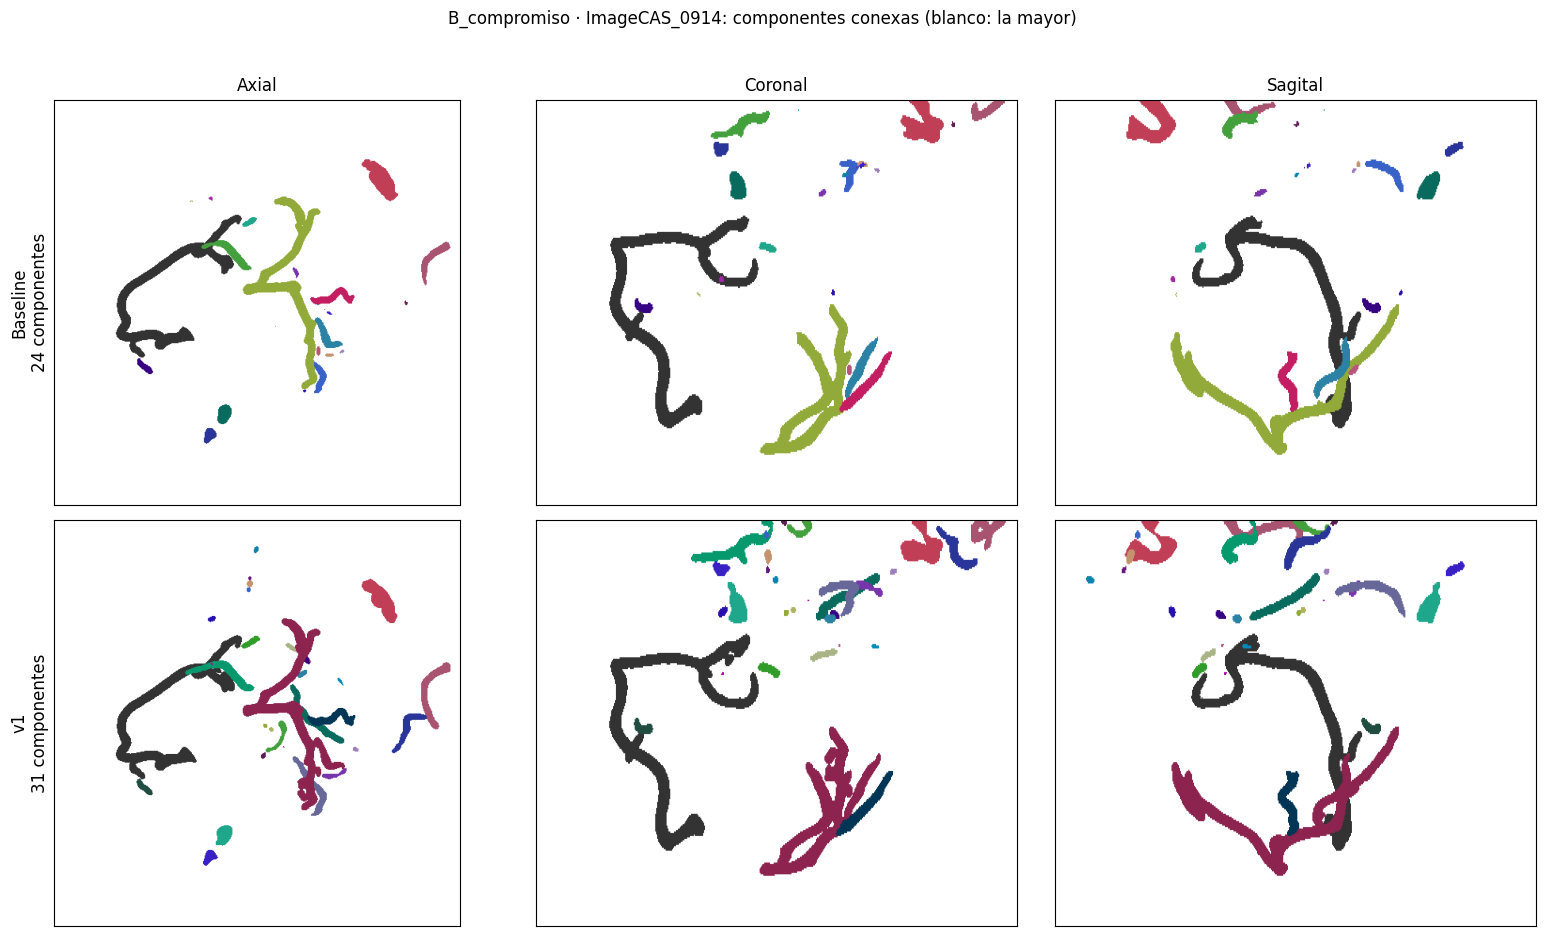

-> fig19_componentes_B_compromiso_ImageCAS_0914.png


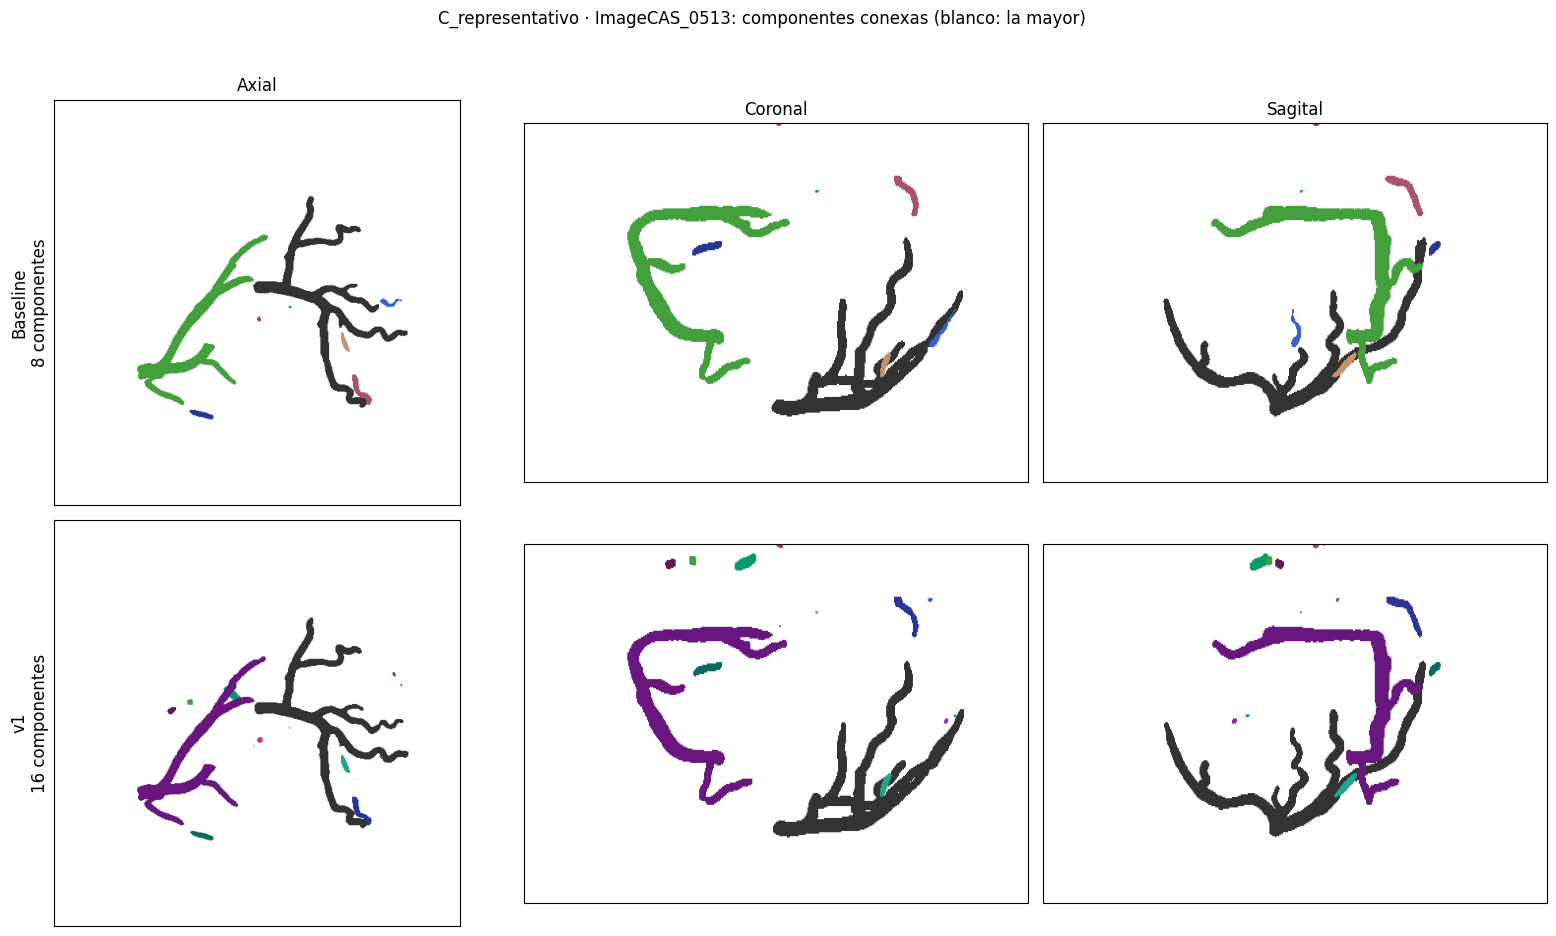

-> fig20_componentes_C_representativo_ImageCAS_0513.png


In [20]:
def componentes_color(mask, eje):
    lab, n = ndimage.label(mask, structure=np.ones((3, 3, 3)))
    if n == 0: return np.full(mask.shape[:eje] + mask.shape[eje + 1:] + (3,), BGV), 0
    tam = ndimage.sum(mask, lab, range(1, n + 1)); mayor = int(np.argmax(tam)) + 1
    rng = np.random.default_rng(1); paleta = rng.uniform(0.0, 0.8, (n + 1, 3)) if BGV == 1 else rng.uniform(0.35, 1.0, (n + 1, 3)); paleta[0] = BGV; paleta[mayor] = TP
    # proyección: se muestra la etiqueta de mayor id (las pequeñas quedan visibles sobre la principal)
    orden = np.where(lab == mayor, 0, lab); proy = np.moveaxis(orden, eje, 0).max(0)
    proy = np.where(proy == 0, np.moveaxis(np.where(lab == mayor, mayor, 0), eje, 0).max(0), proy)
    return paleta[proy], n

def fig_componentes(etiqueta, case_id, fold, fila, nombre):
    gt, preds, sp = cargar_caso(DS_F, TR_F, case_id, fold)
    fig, axes = plt.subplots(2, 3, figsize=(16, 9.5), facecolor=BG)
    for i, (v, eje) in enumerate(VISTAS.items()):
        for j, k in enumerate(('baseline', 'v1')):
            rgb, n = componentes_color(preds[k], eje)
            axes[j, i].imshow(rgb, aspect=aspecto(sp, eje)); axes[j, i].set_xticks([]); axes[j, i].set_yticks([])
            if j == 0: axes[j, i].set_title(v, color=FG)
            if i == 0: axes[j, i].set_ylabel(f"{'Baseline' if k == 'baseline' else 'v1'}\n{n} componentes", color=FG, fontsize=12)
    fig.suptitle(f'{etiqueta} · {case_id}: componentes conexas (blanco: la mayor)', color=FG); fig.tight_layout(rect=[0, 0, 1, 0.96])
    guardar(fig, nombre, 'Discusión: análisis cualitativo', f'Caso {etiqueta}: fragmentación del árbol en baseline y v1')

orden_cmp = {'A_mejora': 18, 'B_compromiso': 19, 'C_representativo': 20}
for _, fila in sel.iterrows():
    fig_componentes(fila['etiqueta'], fila['case_id'], int(fila['fold']), fila, f"fig{orden_cmp[fila['etiqueta']]}_componentes_{fila['etiqueta']}_{fila['case_id']}")

### Figs. 21–23. Superficies 3D suavizadas con TP, FP y FN

Se dibuja la superficie del ground truth acotada al árbol y, sobre ella, los falsos positivos (rojo) y los falsos negativos (azul) de cada modelo.

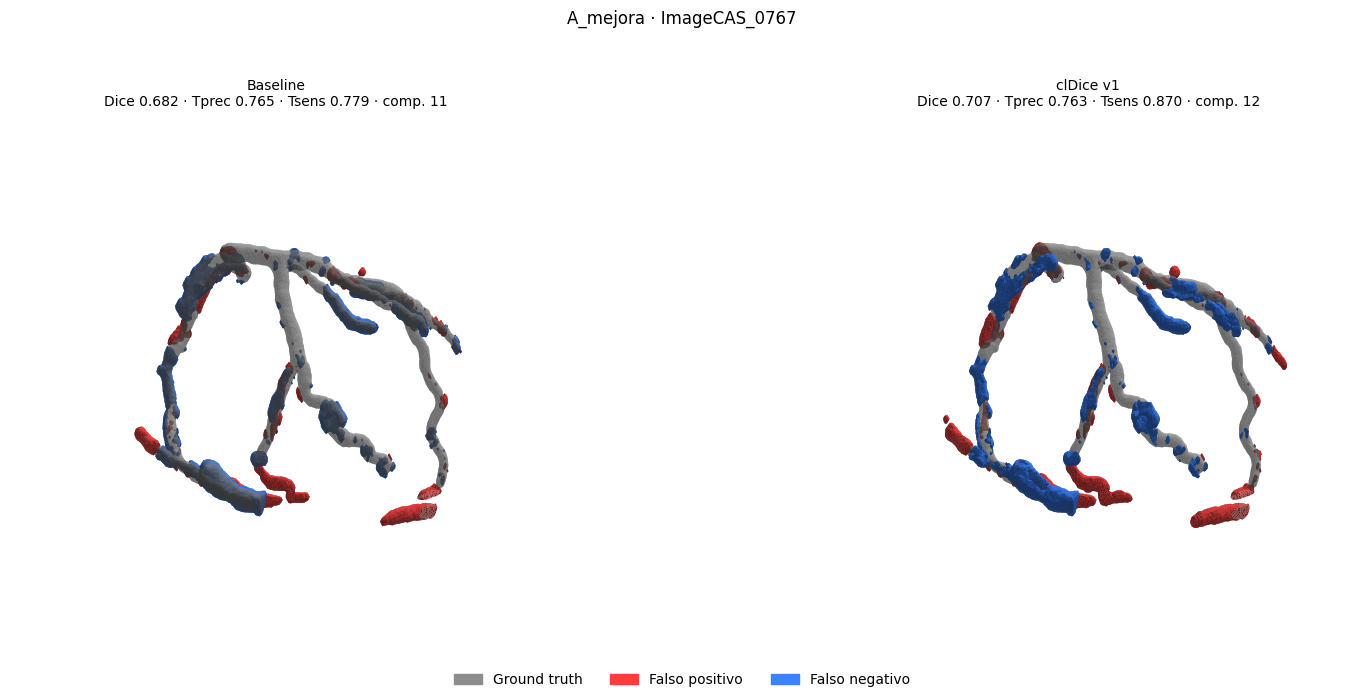

-> fig21_3d_A_mejora_ImageCAS_0767.png


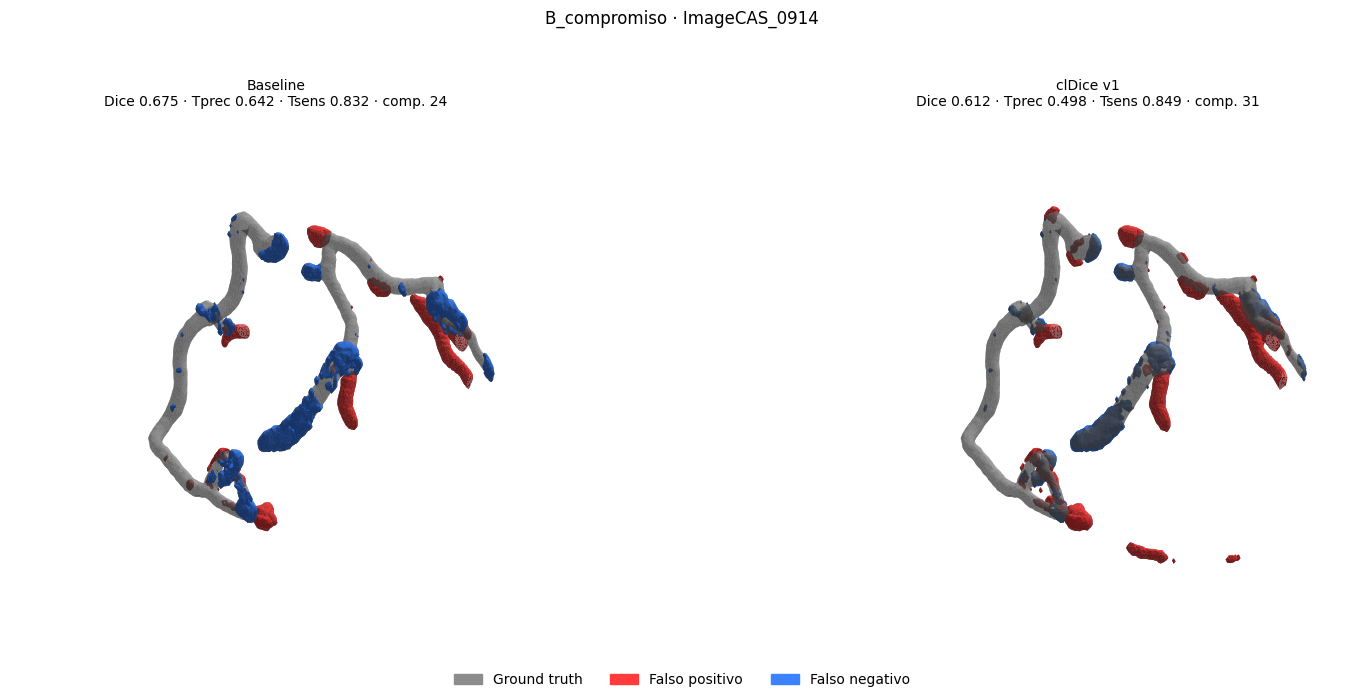

-> fig22_3d_B_compromiso_ImageCAS_0914.png


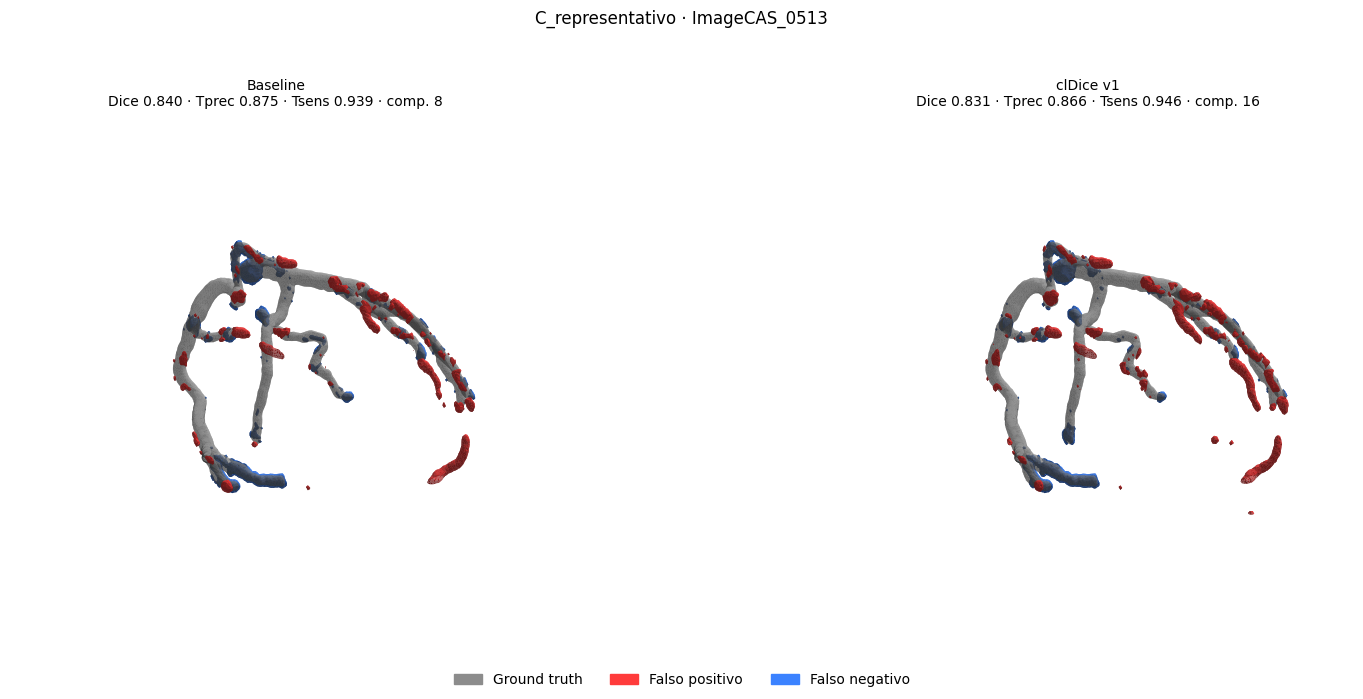

-> fig23_3d_C_representativo_ImageCAS_0513.png


In [21]:
def fig_3d_errores(etiqueta, case_id, fold, fila, nombre):
    gt, preds, sp = cargar_caso(DS_F, TR_F, case_id, fold)
    sl = bbox(gt); g = gt[sl]; fig = plt.figure(figsize=(17, 7), facecolor=BG)
    mg = malla(g, sp, 1.0, 0.5, 2)
    for j, (t, k) in enumerate((('Baseline', 'baseline'), ('clDice v1', 'v1'))):
        p = preds[k][sl]; ax = fig.add_subplot(1, 2, j + 1, projection='3d', facecolor=BG)
        pts = dibujar_malla(ax, mg, GRIS_MALLA, alpha=0.55)
        _, fpm, fnm = errores(p, g)
        for mask, col in ((fpm, '#ff3b3b'), (fnm, '#3b82ff')):
            mm = malla(mask, sp, 0.6, 0.15, 2); dibujar_malla(ax, mm, col)
        ajustar_3d(ax, pts, 25, -60); ax.set_title(f"{t}\n{resumen_caso(fila, '_' + k)}", color=FG, fontsize=10)
    fig.legend(handles=[Patch(color=GRIS_MALLA, label='Ground truth'), Patch(color='#ff3b3b', label='Falso positivo'), Patch(color='#3b82ff', label='Falso negativo')],
               loc='lower center', ncol=3, facecolor=BG, labelcolor=FG, frameon=False)
    fig.suptitle(f'{etiqueta} · {case_id}', color=FG); fig.tight_layout(rect=[0, 0.05, 1, 0.95])
    guardar(fig, nombre, 'Discusión: análisis cualitativo', f'Caso {etiqueta}: visión 3D de aciertos y errores')

orden_3d = {'A_mejora': 21, 'B_compromiso': 22, 'C_representativo': 23}
for _, fila in sel.iterrows():
    fig_3d_errores(fila['etiqueta'], fila['case_id'], int(fila['fold']), fila, f"fig{orden_3d[fila['etiqueta']]}_3d_{fila['etiqueta']}_{fila['case_id']}")

### Figs. 24–26. Corte axial ampliado en la región de mayor diferencia

Se localiza la región de 80×80 píxeles con más vóxeles en los que baseline y v1 discrepan respecto al GT y se muestra el corte axial que más contiene, con CT de fondo si está disponible.

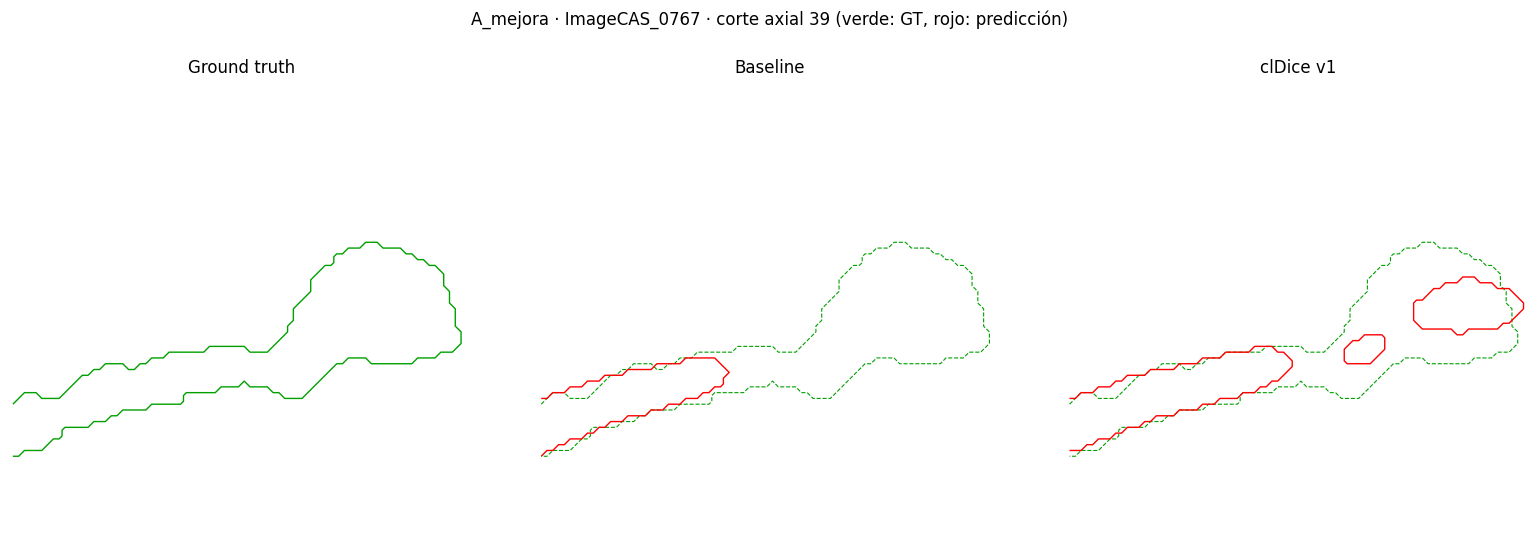

-> fig24_detalle_A_mejora_ImageCAS_0767.png


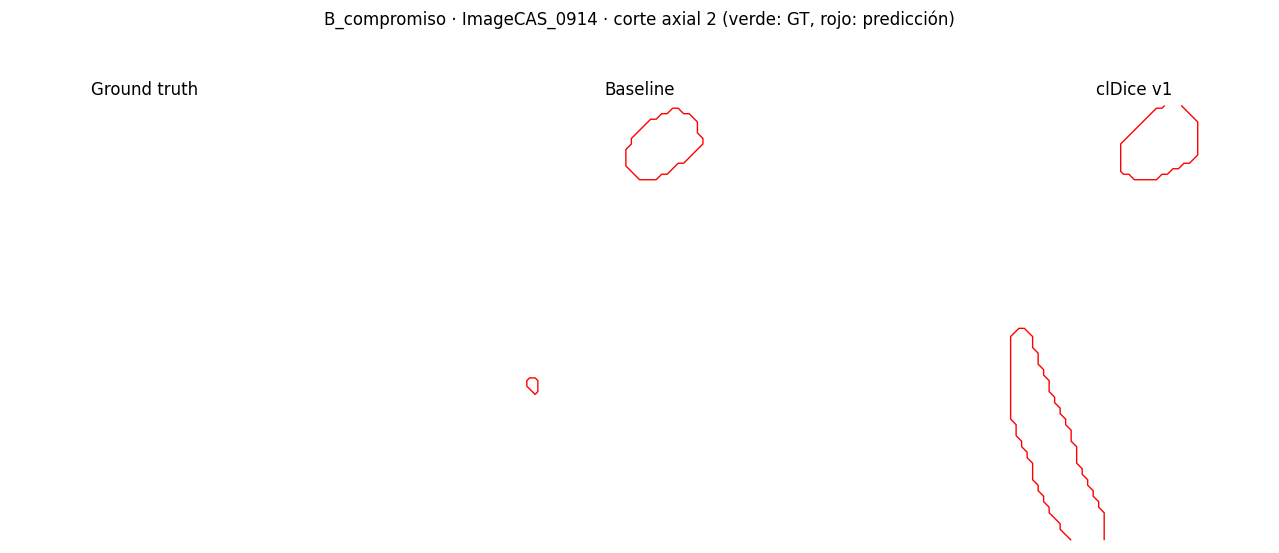

-> fig25_detalle_B_compromiso_ImageCAS_0914.png


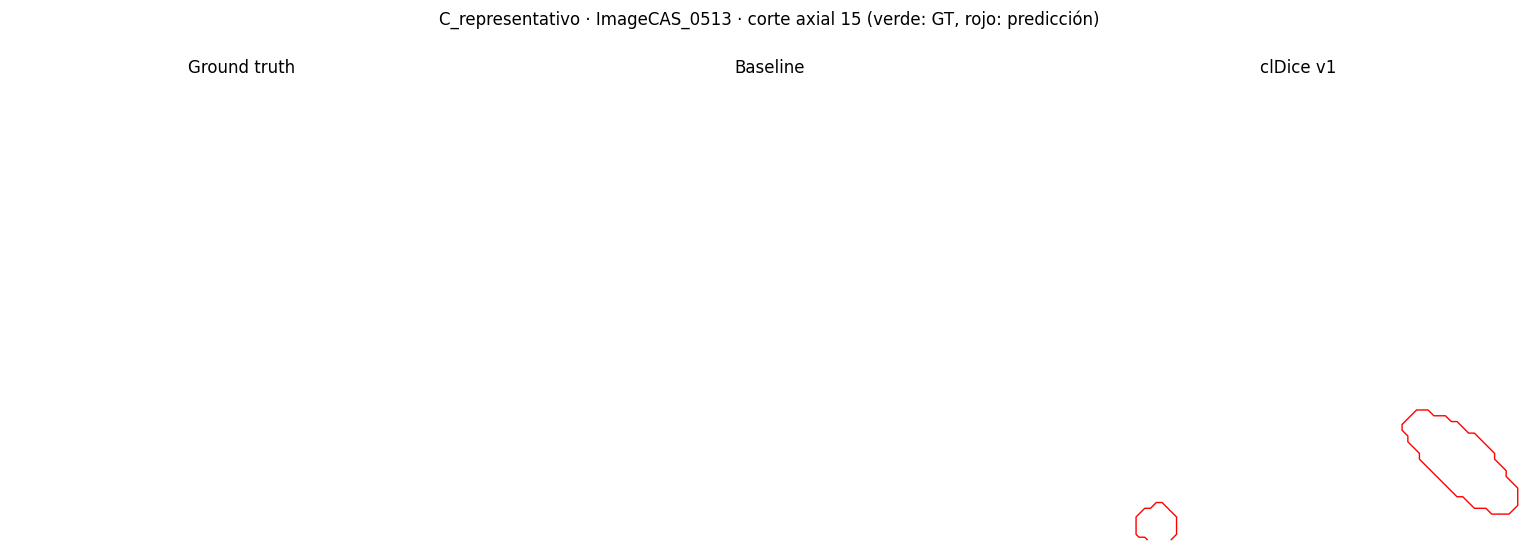

-> fig26_detalle_C_representativo_ImageCAS_0513.png


In [22]:
def fig_detalle(etiqueta, case_id, fold, nombre):
    gt, preds, sp = cargar_caso(DS_F, TR_F, case_id, fold)
    dif = (preds['baseline'] ^ preds['v1'])
    por_corte = dif.sum((1, 2)); z0 = int(np.argmax(por_corte))
    d2 = ndimage.uniform_filter(dif[max(z0 - 2, 0):z0 + 3].any(0).astype(float), size=80); cy, cx = np.unravel_index(np.argmax(d2), d2.shape)
    sl = (slice(max(cy - 40, 0), cy + 40), slice(max(cx - 40, 0), cx + 40))
    ct = cargar_ct(DS_F, case_id); ct = ct if (ct is not None and ct.shape == gt.shape) else None
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.6), facecolor=BG)
    for a, (t, m) in zip(axes, (('Ground truth', gt), ('Baseline', preds['baseline']), ('clDice v1', preds['v1']))):
        fondo = np.clip(ct[z0][sl], -200, 600) if ct is not None else np.full(gt[z0][sl].shape, BGV)
        a.imshow(fondo, cmap='gray', aspect=sp[1] / sp[2], interpolation='nearest', **({} if ct is not None else dict(vmin=0, vmax=1)))
        if t == 'Ground truth': a.contour(gt[z0][sl], levels=[0.5], colors='#00a000' if BGV == 1 else 'lime', linewidths=1)
        else:
            a.contour(gt[z0][sl], levels=[0.5], colors='#00a000' if BGV == 1 else 'lime', linewidths=0.8, linestyles='--'); a.contour(m[z0][sl], levels=[0.5], colors='red', linewidths=1)
        a.set_title(t, color=FG); a.axis('off')
    fig.suptitle(f'{etiqueta} · {case_id} · corte axial {z0} (verde: GT, rojo: predicción)', color=FG); fig.tight_layout(rect=[0, 0, 1, 0.94])
    guardar(fig, nombre, 'Discusión: análisis cualitativo', f'Caso {etiqueta}: detalle local de la región de mayor discrepancia')

orden_det = {'A_mejora': 24, 'B_compromiso': 25, 'C_representativo': 26}
for _, fila in sel.iterrows():
    fig_detalle(fila['etiqueta'], fila['case_id'], int(fila['fold']), f"fig{orden_det[fila['etiqueta']]}_detalle_{fila['etiqueta']}_{fila['case_id']}")

## 8. Índice de figuras generadas

Tabla con el archivo, el apartado de la memoria en el que se propone insertar cada figura y el mensaje que sustenta, en el orden sugerido de aparición. La numeración definitiva (Ilustración N) se asigna al insertarlas en el documento.

In [23]:
idx = pd.DataFrame(FIGS, columns=['archivo', 'apartado_memoria', 'mensaje'])
idx.to_csv(OUT / 'indice_figuras.csv', index=False)
pd.set_option('display.max_colwidth', 120)
display(idx)
print('Carpeta de salida:', OUT)

,archivo,apartado_memoria,mensaje
0,fig01_esqueleto_centerline.png,Marco teórico: clDice y esqueletonización,"Esqueleto de un vóxel de grosor (centerline) sobre el que se definen Tprec, Tsens y clDice"
1,fig02_arbol_gt.png,Datos: ImageCAS,"Anatomía, extensión y finura del árbol coronario anotado"
2,fig04_grosor_y_deep_supervision.png,Experimento 3 (justificación de v2) y discusión,Los vasos de 1–3 vóxeles apenas sobreviven en las escalas reducidas de deep supervision
3,fig05_piloto_mejora_ImageCAS_0131.png,Resultados de la fase piloto,"Comparación visual de baseline, v1 y v2 frente al ground truth"
4,fig05_piloto_empeora_ImageCAS_0146.png,Resultados de la fase piloto,"Comparación visual de baseline, v1 y v2 frente al ground truth"
5,fig06_piloto_distribucion_metricas.png,Resultados de la fase piloto,Dispersión entre casos (n = 40) que la media de la tabla no muestra
6,fig07_piloto_barrido_lambda.png,Selección de λ (piloto),Barrido manual de λ: diferencias pequeñas entre valores
7,fig08_1000_distribucion_delta.png,Resultado agregado (1.000 casos),Magnitud del efecto por caso y proporción de casos en que v1 mejora
8,fig09_1000_delta_por_fold.png,Resultado por fold (1.000 casos),Consistencia del efecto entre particiones
9,fig10_1000_tradeoff_tprec_tsens.png,Resultado por fold (1.000 casos),v1 intercambia precisión topológica por sensibilidad topológica


Carpeta de salida: /content/drive/MyDrive/TFM_nnUNet/figuras_memoria
